# TC2004B - Análisis de Ciencia de Datos
## Evaluación de métricas, evaluación cruzada y optimización de hiperparametros

### Importar Librerías

In [ ]:
!pip install xgboost

In [ ]:
# ======================================================================
# 0. Imports
# ======================================================================
# Librerías básicas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

# Preprocesamiento y transformación
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Reducción de dimensionalidad
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Selección de modelos y validación
from sklearn.model_selection import (
    train_test_split, GridSearchCV, RandomizedSearchCV,
    cross_val_score, StratifiedKFold
)

# Métricas
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Modelos de clasificación
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Feature selection
from sklearn.feature_selection import RFE

# Configuración visual de los pipelines
from sklearn import set_config


### Limpieza de Datos

In [ ]:
#Limpieza de datos

#importar archivo
df=pd.read_csv('MarketingCampaign.csv')
df.head()
print(df.describe())

print(df.isna())#checar null y na
print(df.isnull())
df.info()
print(df['Marital_Status'].unique())

#saber que columnas no son int para pasarlas a categoricas
difInt= df.select_dtypes(exclude='int64').columns
for i in difInt:
    print(df[i].unique())
'''
le=LabelEncoder() #transformar variables categoricas
for col in difInt:
    df[col]=le.fit_transform(df[col])

#escalar los datos
'''

                 ID   Year_Birth         Income      Kidhome     Teenhome  \
count   2240.000000  2240.000000    2216.000000  2240.000000  2240.000000   
mean    5592.159821  1968.805804   52247.251354     0.444196     0.506250   
std     3246.662198    11.984069   25173.076661     0.538398     0.544538   
min        0.000000  1893.000000    1730.000000     0.000000     0.000000   
25%     2828.250000  1959.000000   35303.000000     0.000000     0.000000   
50%     5458.500000  1970.000000   51381.500000     0.000000     0.000000   
75%     8427.750000  1977.000000   68522.000000     1.000000     1.000000   
max    11191.000000  1996.000000  666666.000000     2.000000     2.000000   

           Recency     MntWines    MntFruits  MntMeatProducts  \
count  2240.000000  2240.000000  2240.000000      2240.000000   
mean     49.109375   303.935714    26.302232       166.950000   
std      28.962453   336.597393    39.773434       225.715373   
min       0.000000     0.000000     0.000000  

'\nle=LabelEncoder() #transformar variables categoricas\nfor col in difInt:\n    df[col]=le.fit_transform(df[col])\n\n#escalar los datos\n'

### Preprocesamiento de Datos

In [ ]:
# Preprocesamiento
def preprocess_data(df):
    # Eliminar columnas constantes/innecesarias
    try:
      df = df.drop(['ID', 'Z_CostContact', 'Z_Revenue'], axis=1)


      # Calcular edad
      current_year = 2025
      df['Age'] = current_year - df['Year_Birth']
      df = df.drop('Year_Birth', axis=1)

      # Convertir fecha a antigüedad como cliente
      df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'], format='%d/%m/%y')
      latest_date = df['Dt_Customer'].max()
      df['Customer_For'] = (latest_date - df['Dt_Customer']).dt.days
      df = df.drop('Dt_Customer', axis=1)

      # Crear nuevas características
      df['Total_Children'] = df['Kidhome'] + df['Teenhome']
      df['Total_Spending'] = df[['MntWines', 'MntFruits', 'MntMeatProducts',
                                'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']].sum(axis=1)
      df['Total_Purchases'] = df[['NumWebPurchases', 'NumCatalogPurchases',
                                'NumStorePurchases', 'NumDealsPurchases']].sum(axis=1)

      # Consolidar estado civil
      df['Marital_Status'] = df['Marital_Status'].replace({
          'Married': 'Partner',
          'Together': 'Partner',
          'Single': 'Single',
          'Divorced': 'Single',
          'Widow': 'Single',
          'Alone': 'Single',
          'Absurd': 'Single',
          'YOLO': 'Single'
      })

      # Consolidar educación
      education_order = {'Basic': 0, '2n Cycle': 1, 'Graduation': 2, 'Master': 3, 'PhD': 4}
      df['Education'] = df['Education'].map(education_order)
    except:
      pass
    return df

df = preprocess_data(df)
print(df.info())

df_copy = df.copy()

y = df_copy.pop('Response')
X = df_copy

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Education            2240 non-null   int64  
 1   Marital_Status       2240 non-null   object 
 2   Income               2216 non-null   float64
 3   Kidhome              2240 non-null   int64  
 4   Teenhome             2240 non-null   int64  
 5   Recency              2240 non-null   int64  
 6   MntWines             2240 non-null   int64  
 7   MntFruits            2240 non-null   int64  
 8   MntMeatProducts      2240 non-null   int64  
 9   MntFishProducts      2240 non-null   int64  
 10  MntSweetProducts     2240 non-null   int64  
 11  MntGoldProds         2240 non-null   int64  
 12  NumDealsPurchases    2240 non-null   int64  
 13  NumWebPurchases      2240 non-null   int64  
 14  NumCatalogPurchases  2240 non-null   int64  
 15  NumStorePurchases    2240 non-null   i

### Análisis Exploratorio

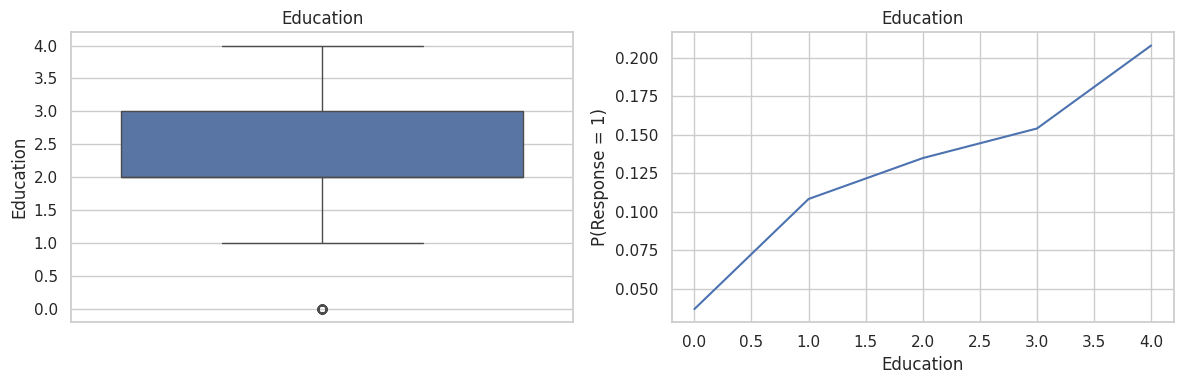

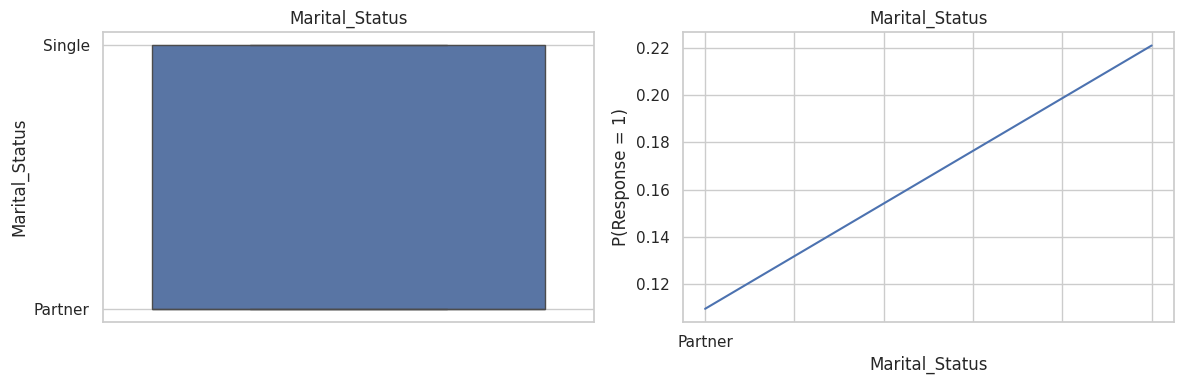

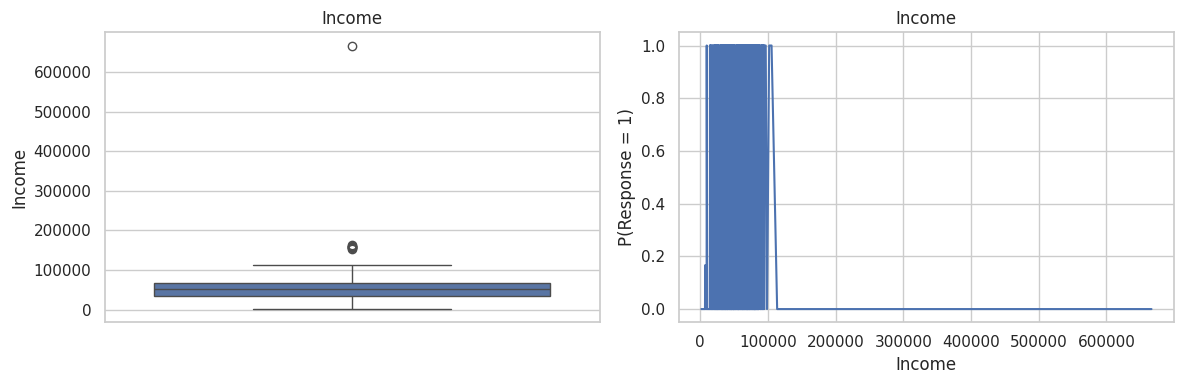

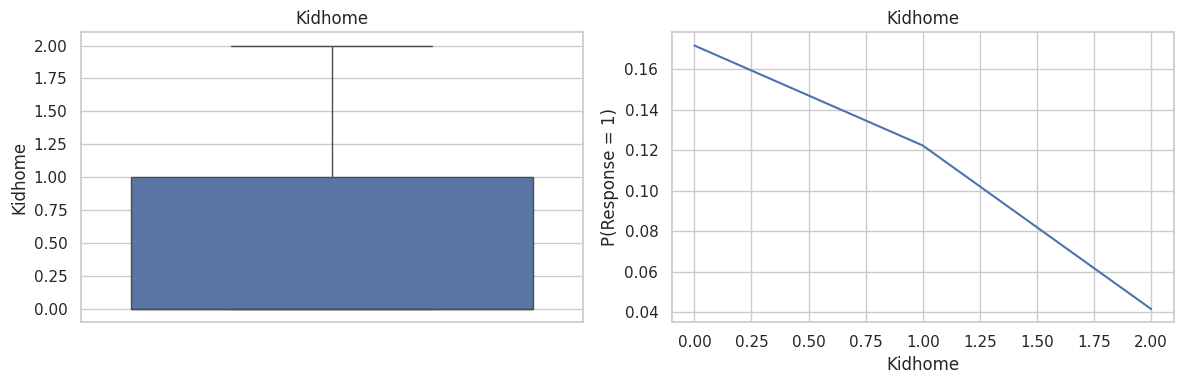

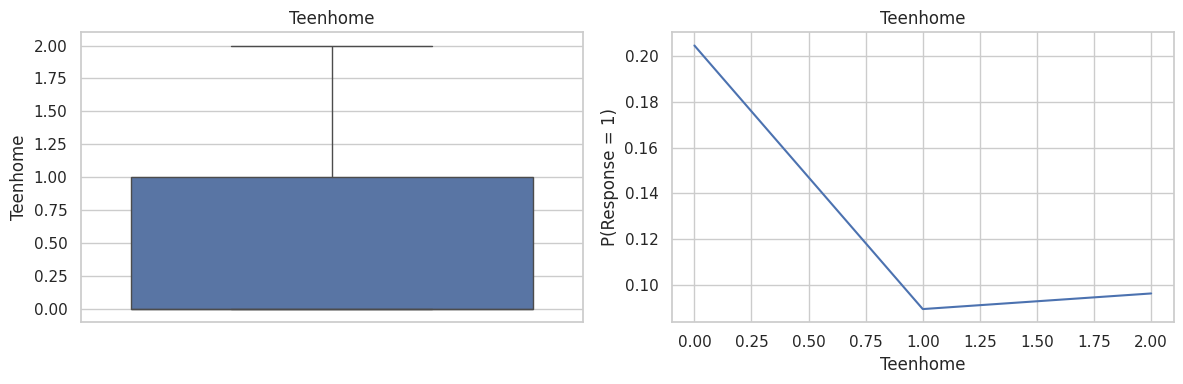

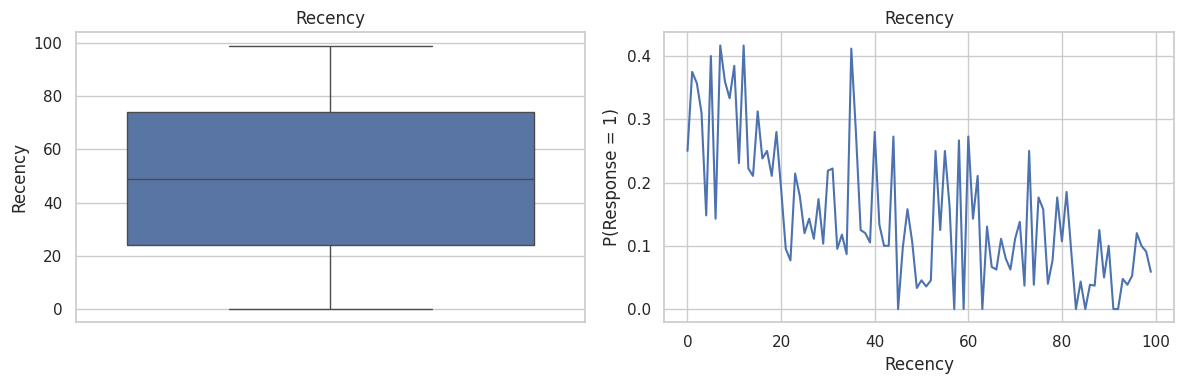

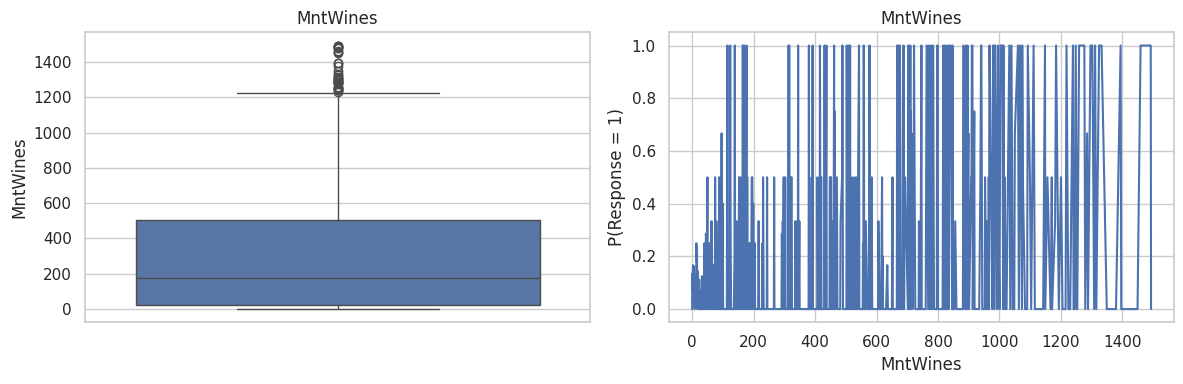

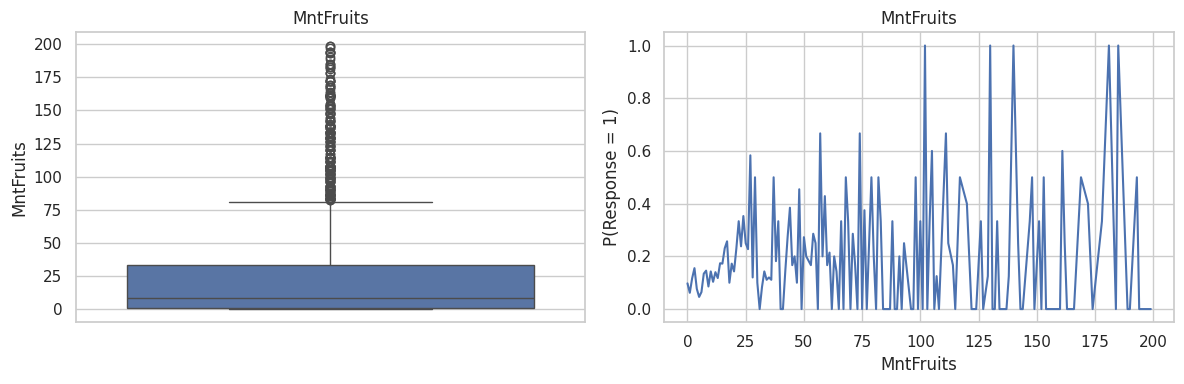

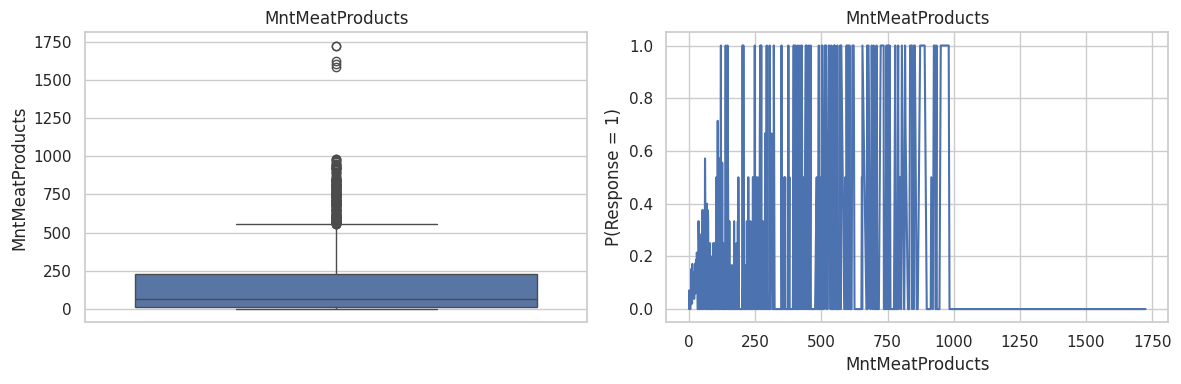

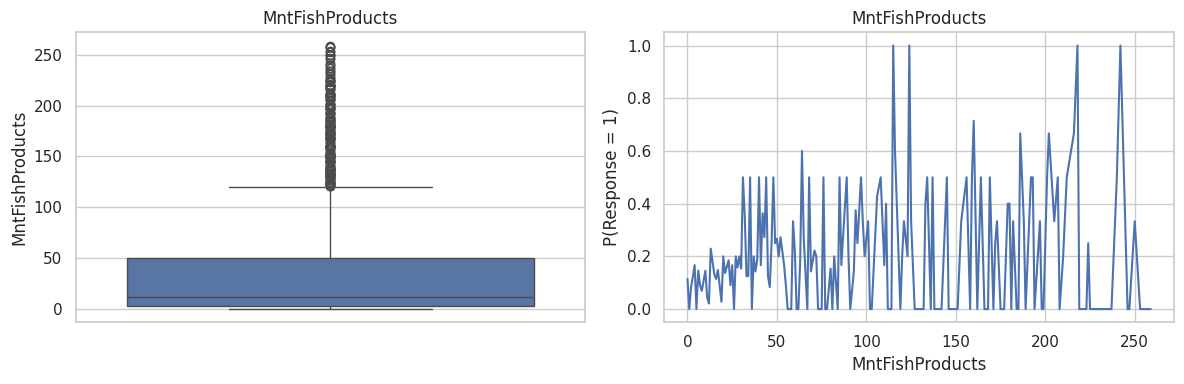

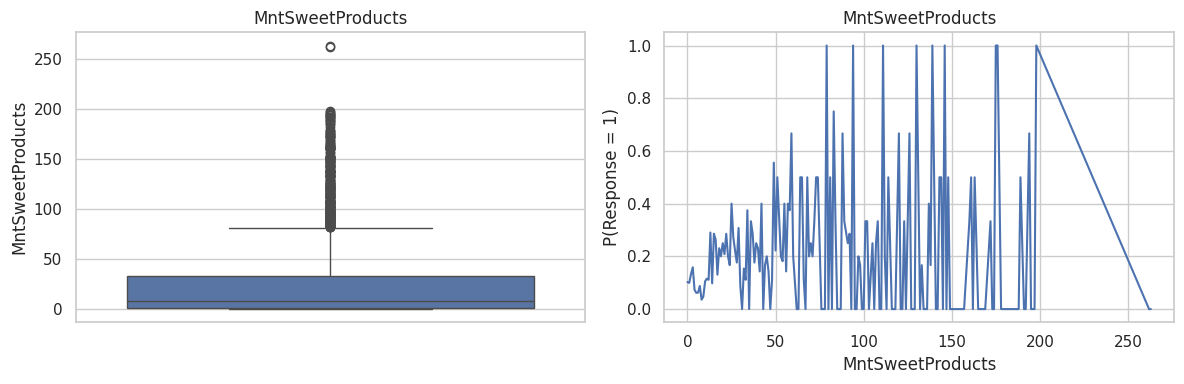

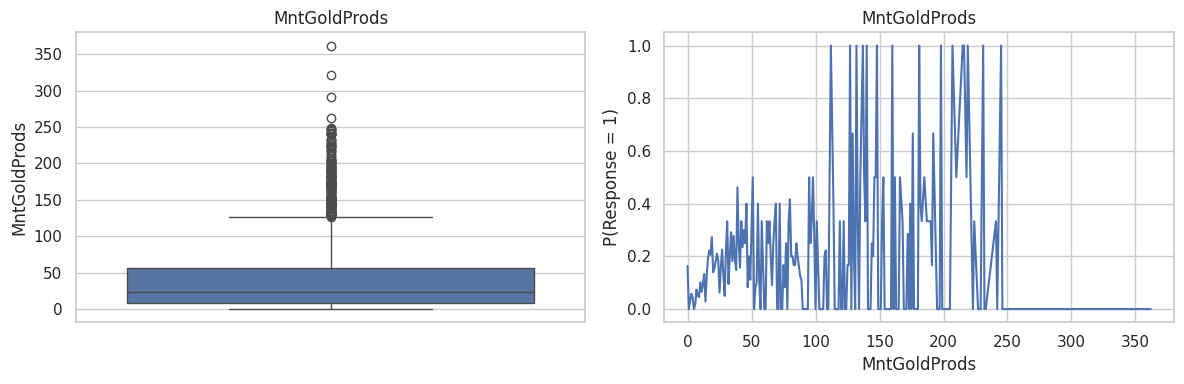

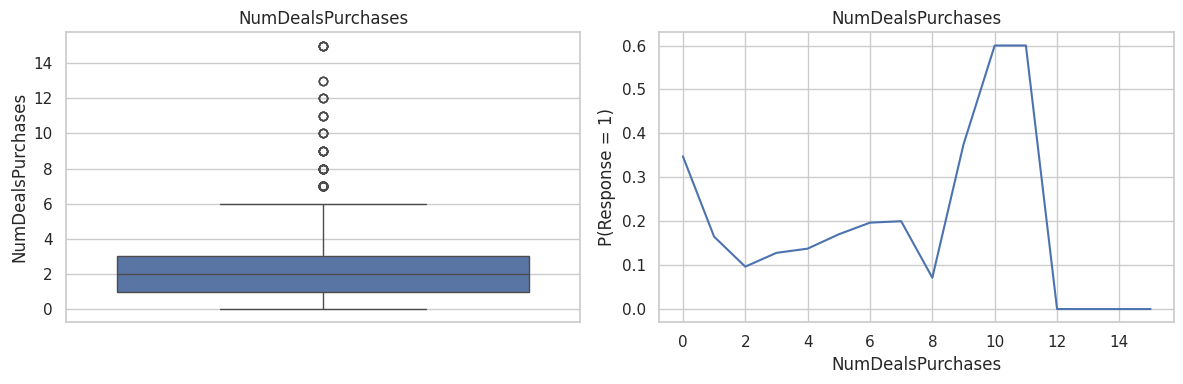

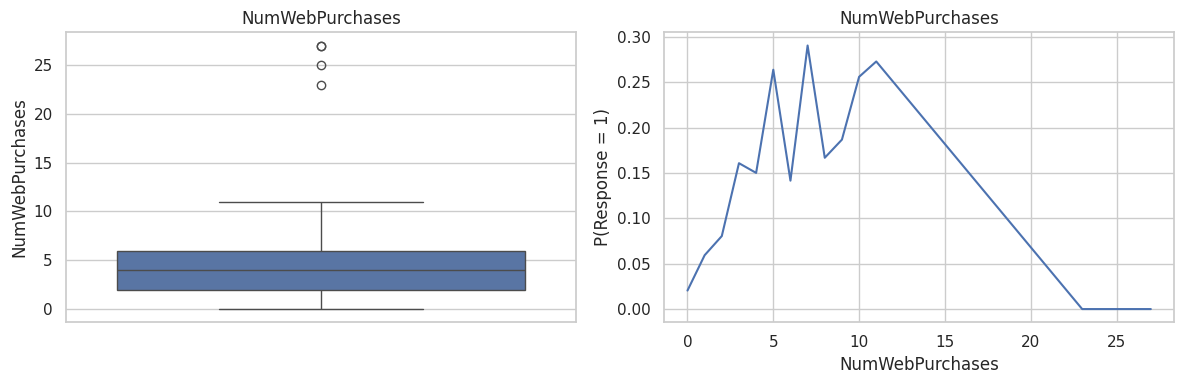

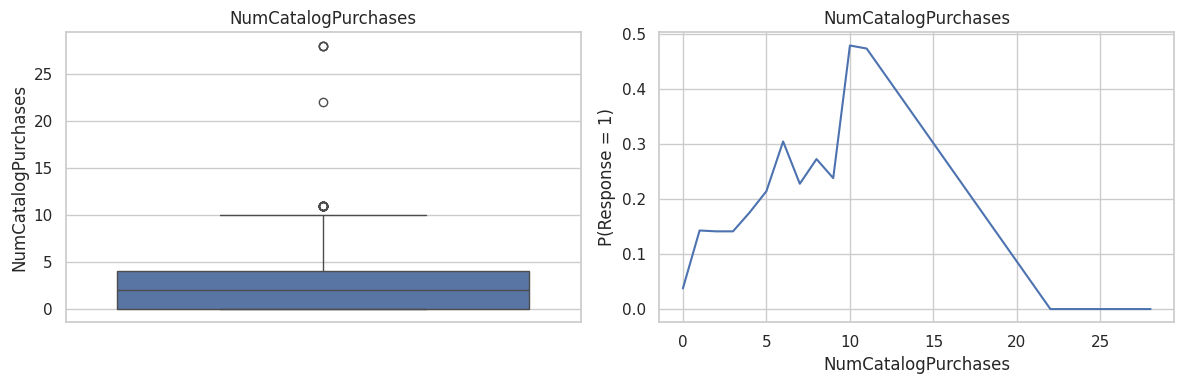

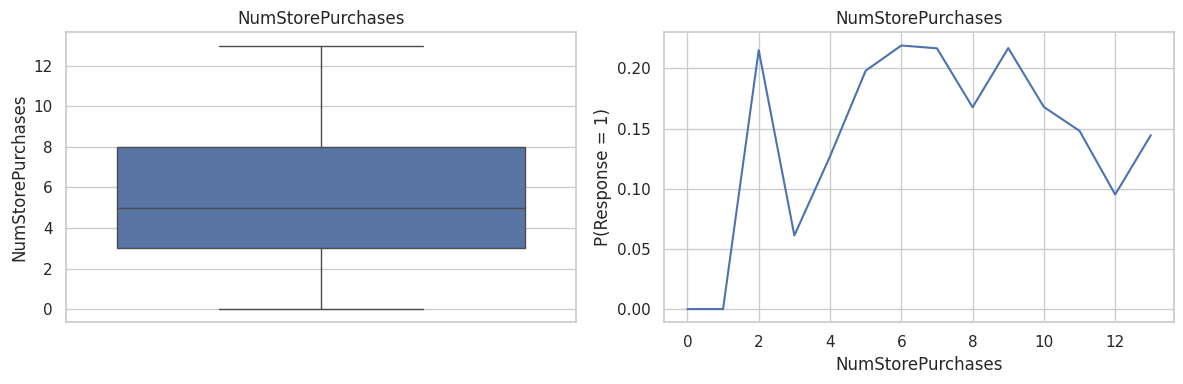

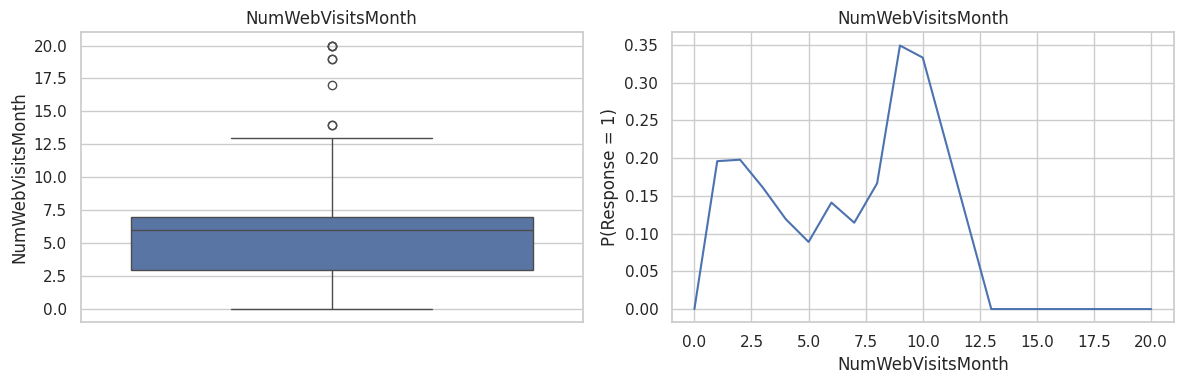

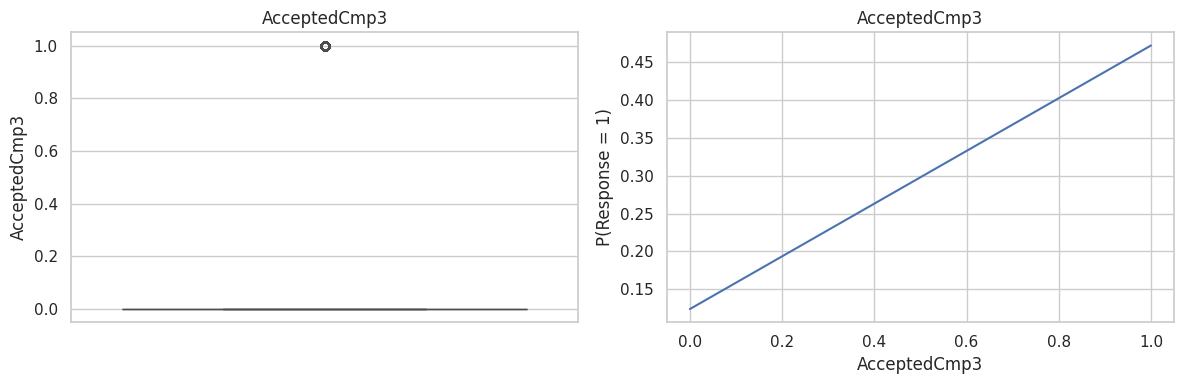

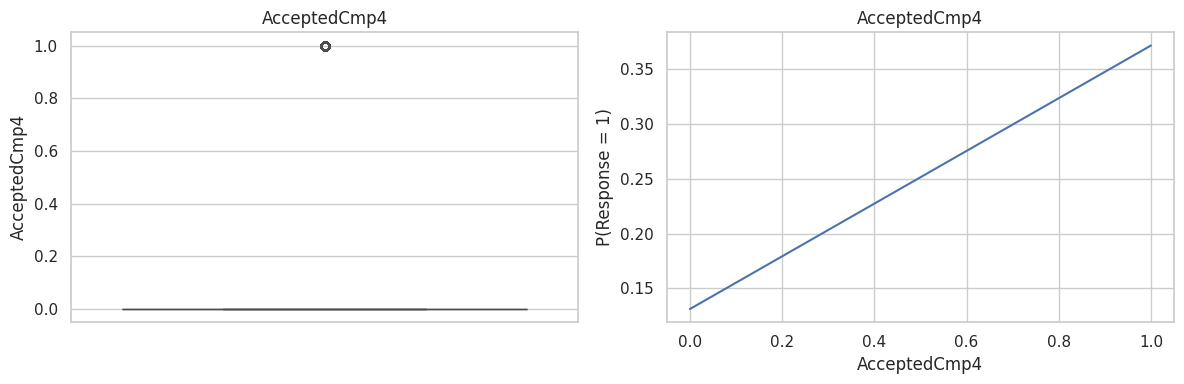

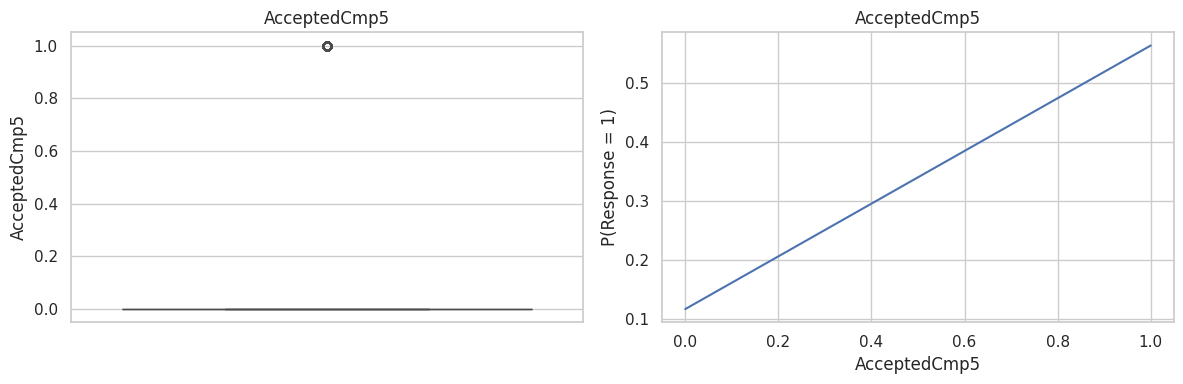

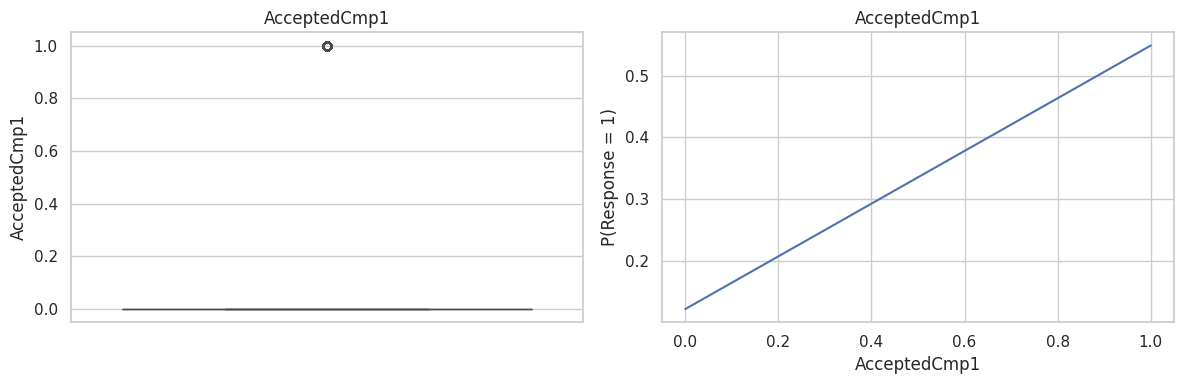

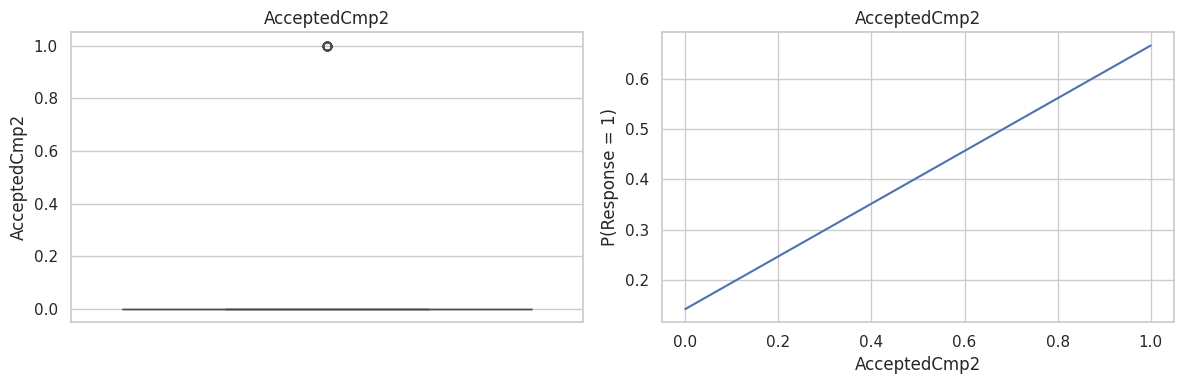

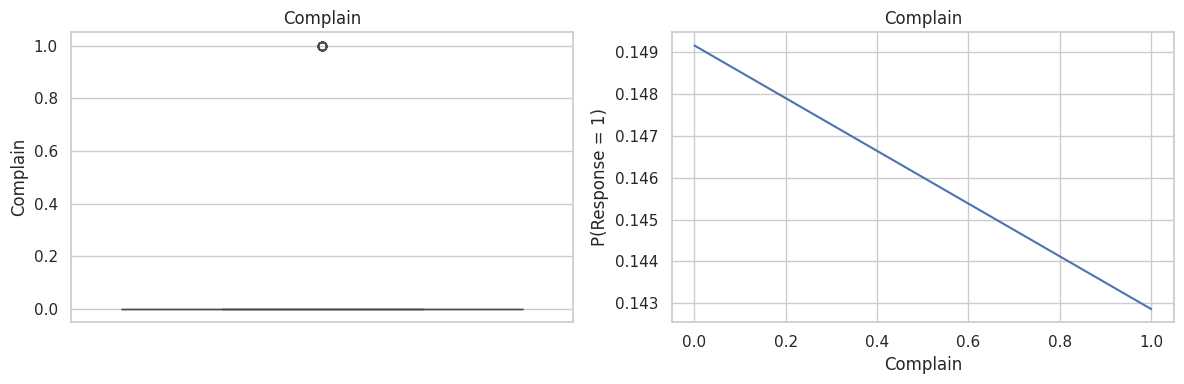

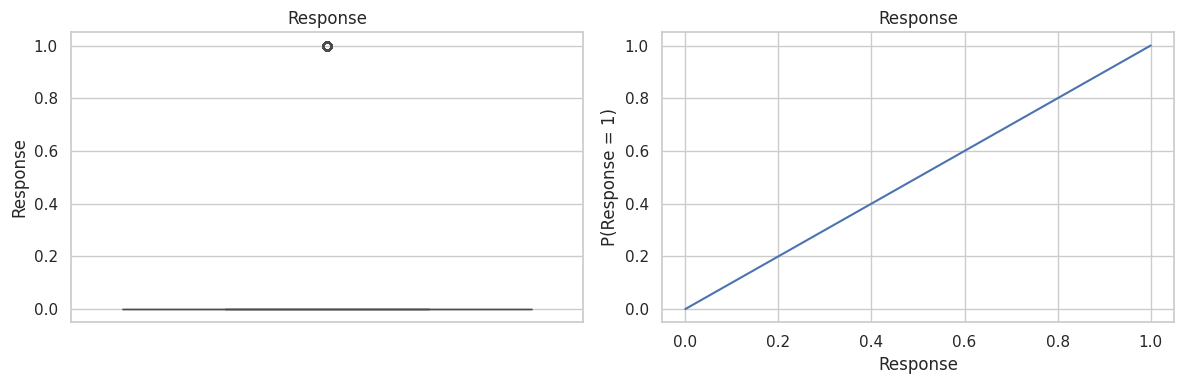

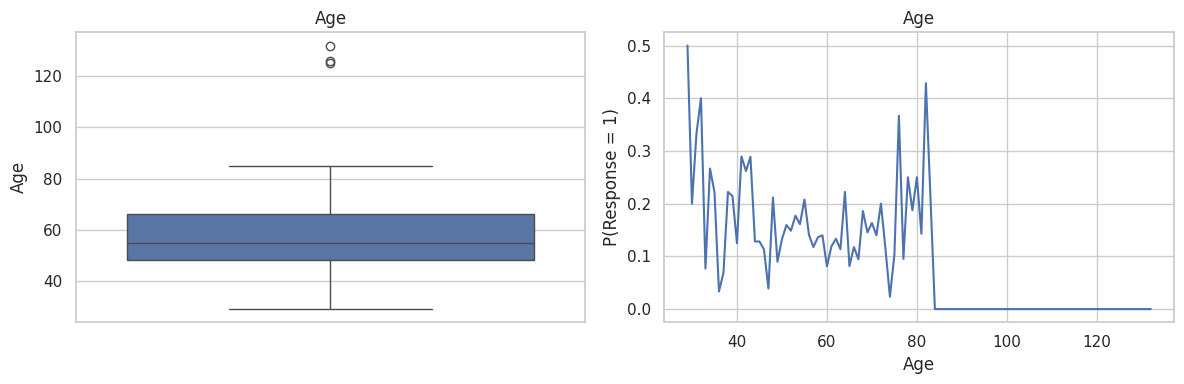

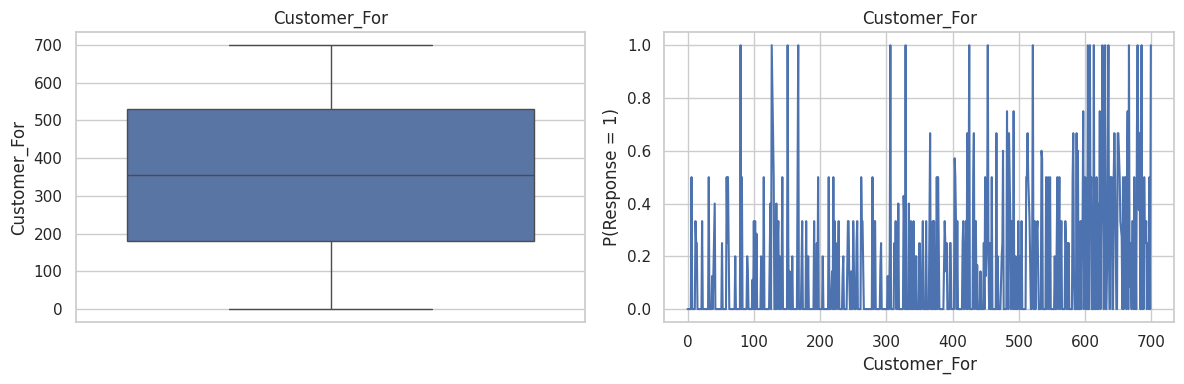

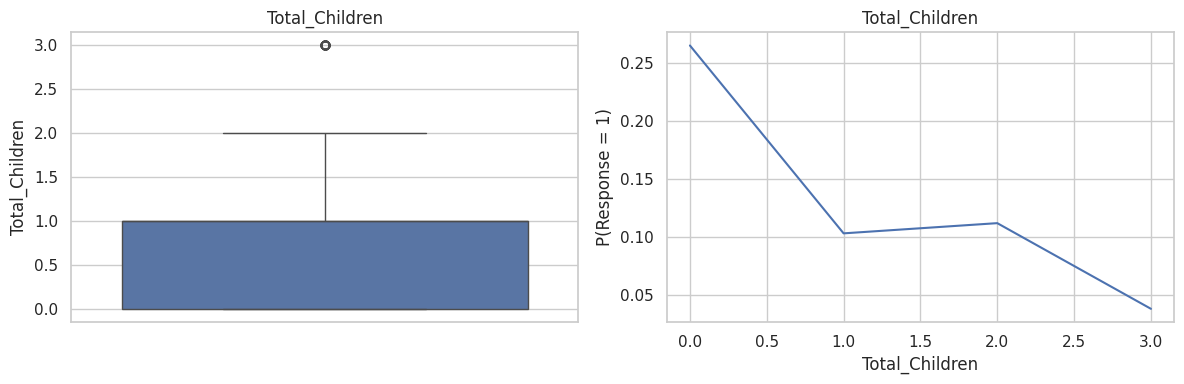

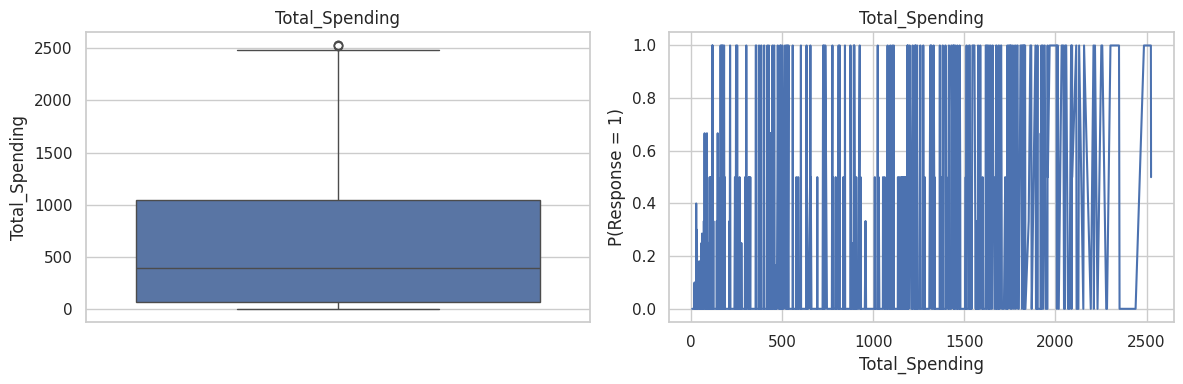

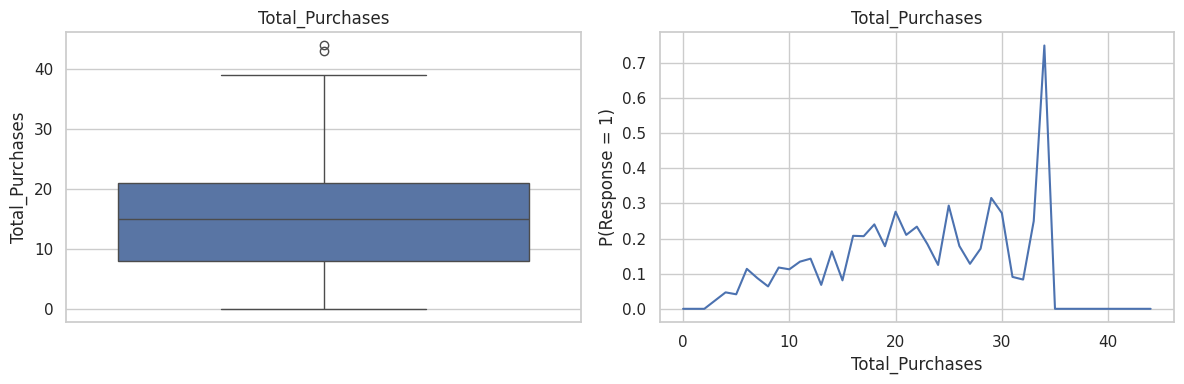

<ipython-input-150-52dc777474fc>:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(column)["Response"].mean().plot(


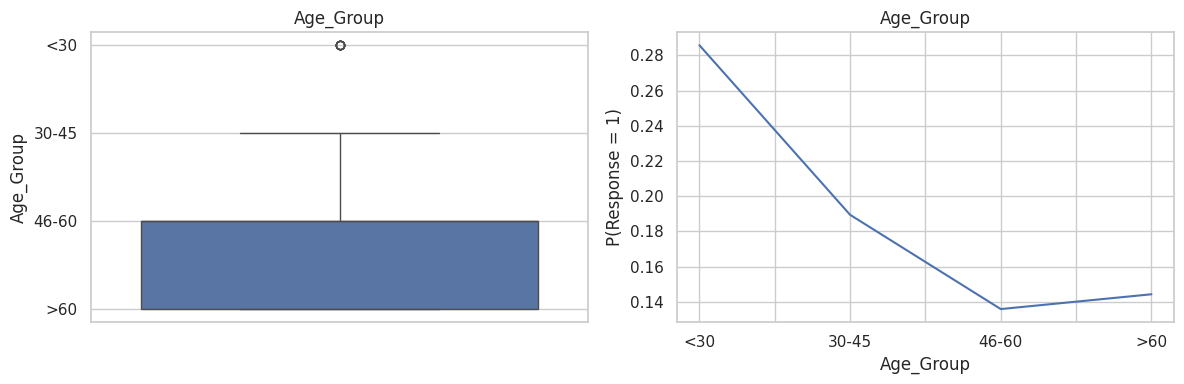

'\n## Para regresión logística, k-means, knn ocupa escalar datos pero tener datos escalados en arboles\nde decision, random forest, xgboost no se ven perjudicados así que lo escalaré desde el inicio.\n'

In [ ]:

df.head()
df.describe()

# Ver si no hay outliers para saber que método para estandarizar usar
for column in df.columns:

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))  # 1 fila, 2 columnas

    sns.boxplot(data=df[column], ax=axes[0]).set(title=column)

    df.groupby(column)["Response"].mean().plot(
      ax=axes[1],
      title=column,
      ylabel="P(Response = 1)",
      xlabel=column
    )

    plt.tight_layout()
    plt.show()

#Como hay muchos outliers utilizaré Robust Scaler
'''
## Para regresión logística, k-means, knn ocupa escalar datos pero tener datos escalados en arboles
de decision, random forest, xgboost no se ven perjudicados así que lo escalaré desde el inicio.
'''




<ipython-input-142-ed849a53bf4f>:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Age_Group', y='Income', data=df, palette='viridis', order=age_labels)


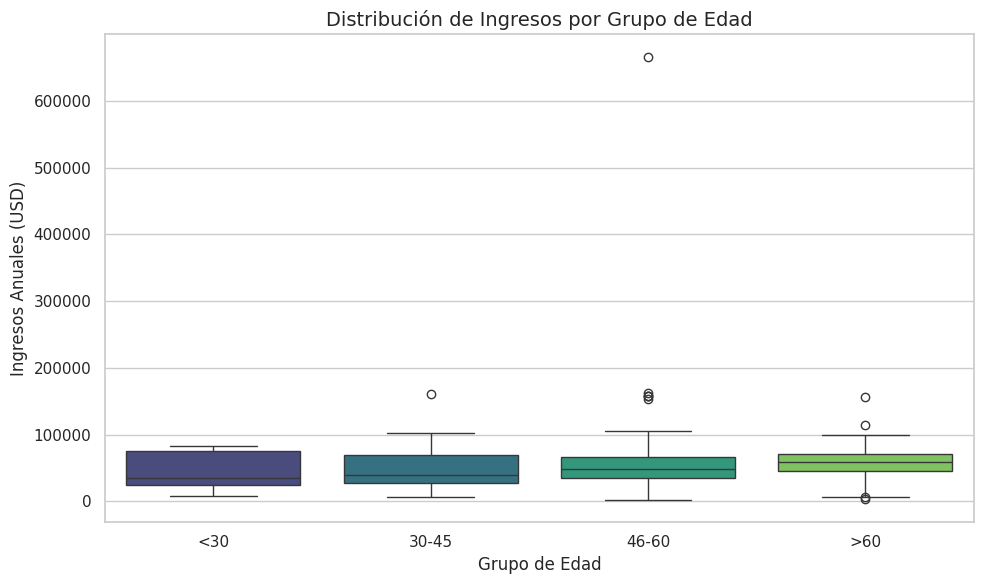

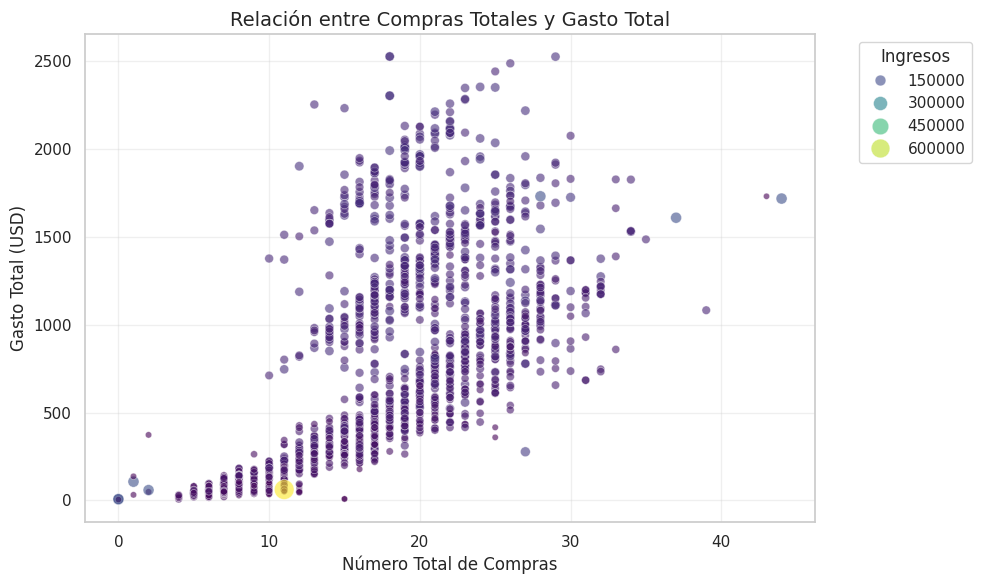

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 30 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   Education            2240 non-null   int64   
 1   Marital_Status       2240 non-null   object  
 2   Income               2216 non-null   float64 
 3   Kidhome              2240 non-null   int64   
 4   Teenhome             2240 non-null   int64   
 5   Recency              2240 non-null   int64   
 6   MntWines             2240 non-null   int64   
 7   MntFruits            2240 non-null   int64   
 8   MntMeatProducts      2240 non-null   int64   
 9   MntFishProducts      2240 non-null   int64   
 10  MntSweetProducts     2240 non-null   int64   
 11  MntGoldProds         2240 non-null   int64   
 12  NumDealsPurchases    2240 non-null   int64   
 13  NumWebPurchases      2240 non-null   int64   
 14  NumCatalogPurchases  2240 non-null   int64   
 15  NumStorePurchases    

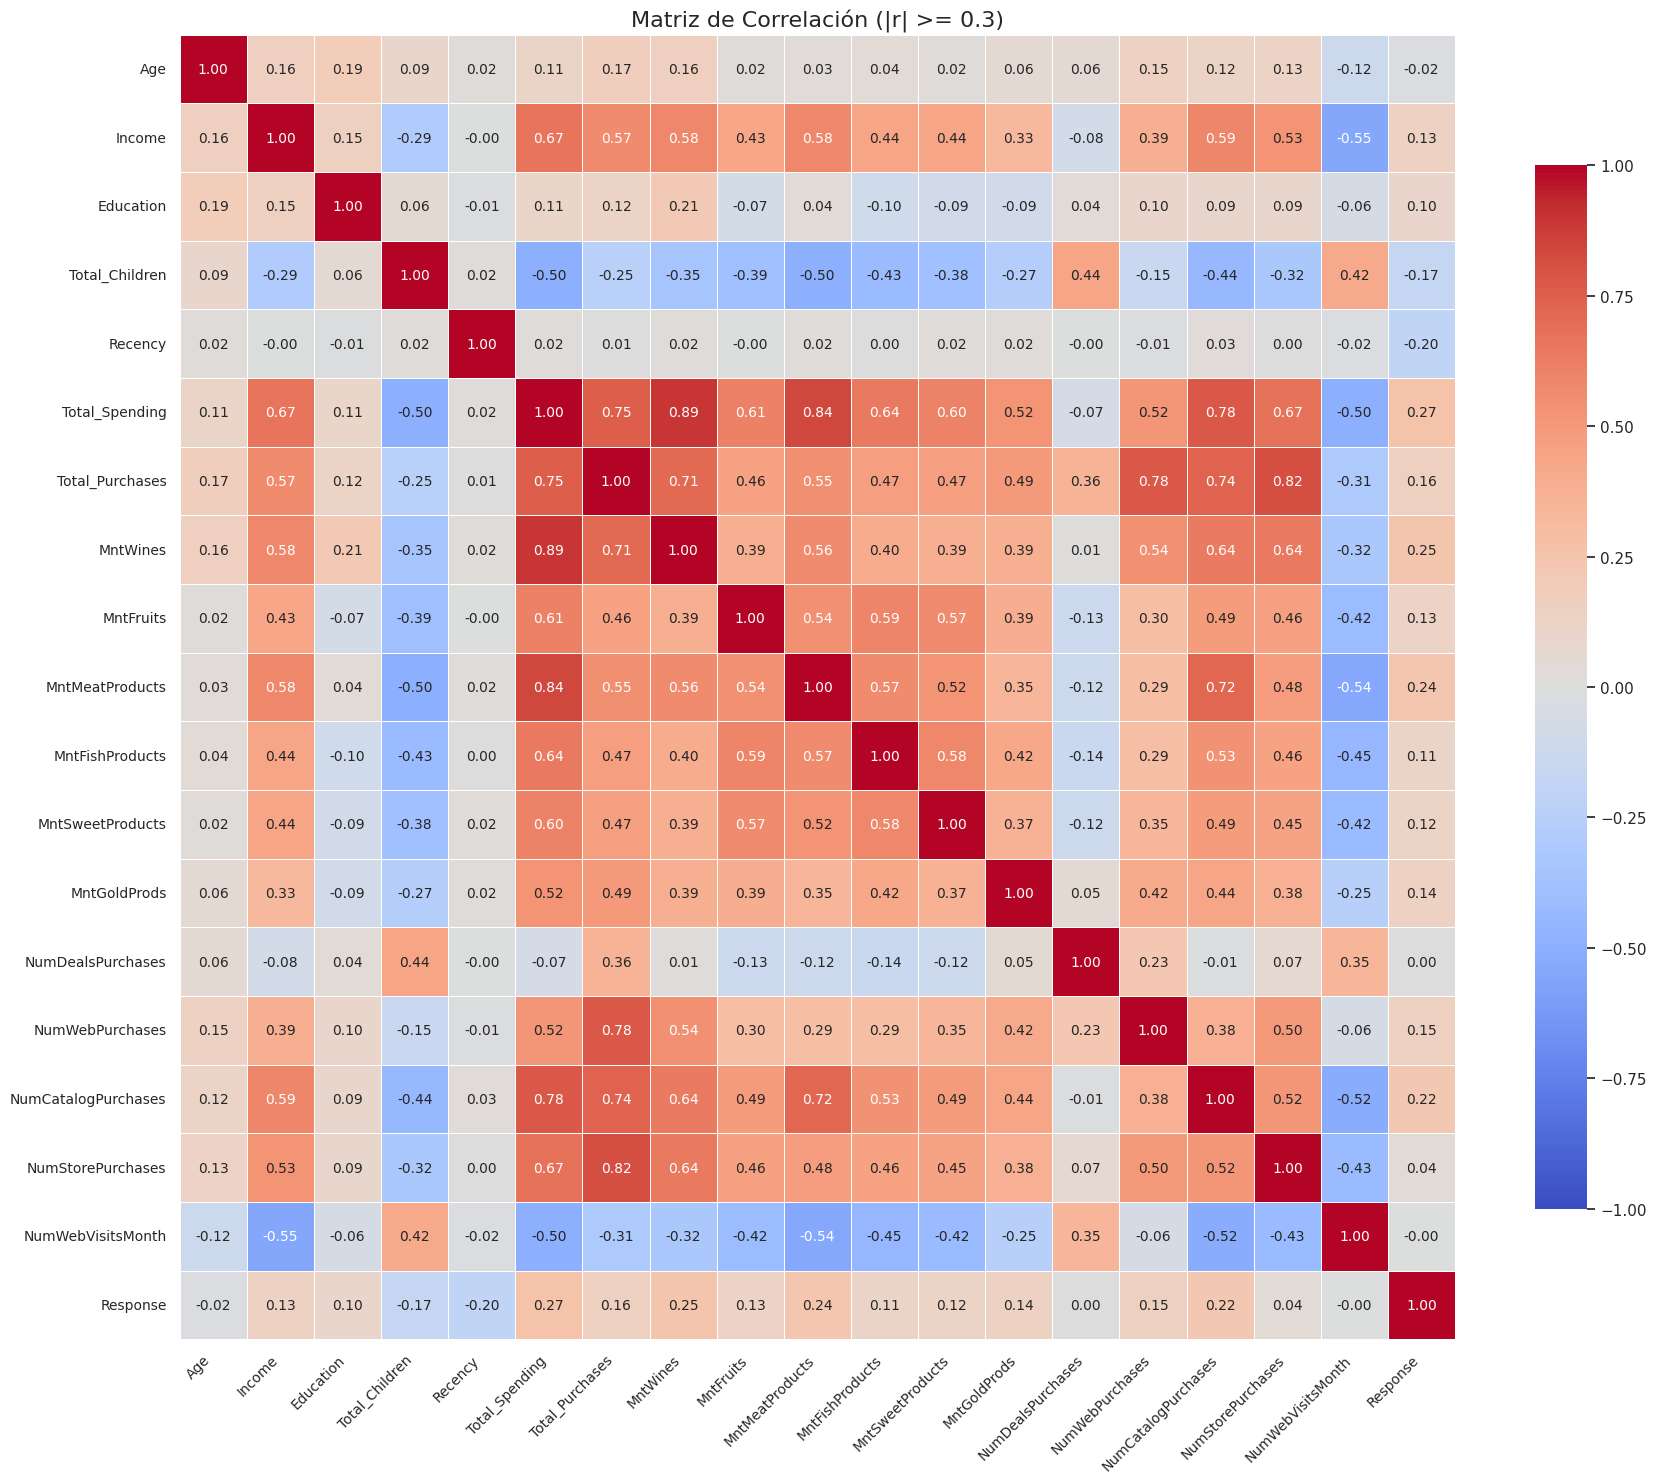

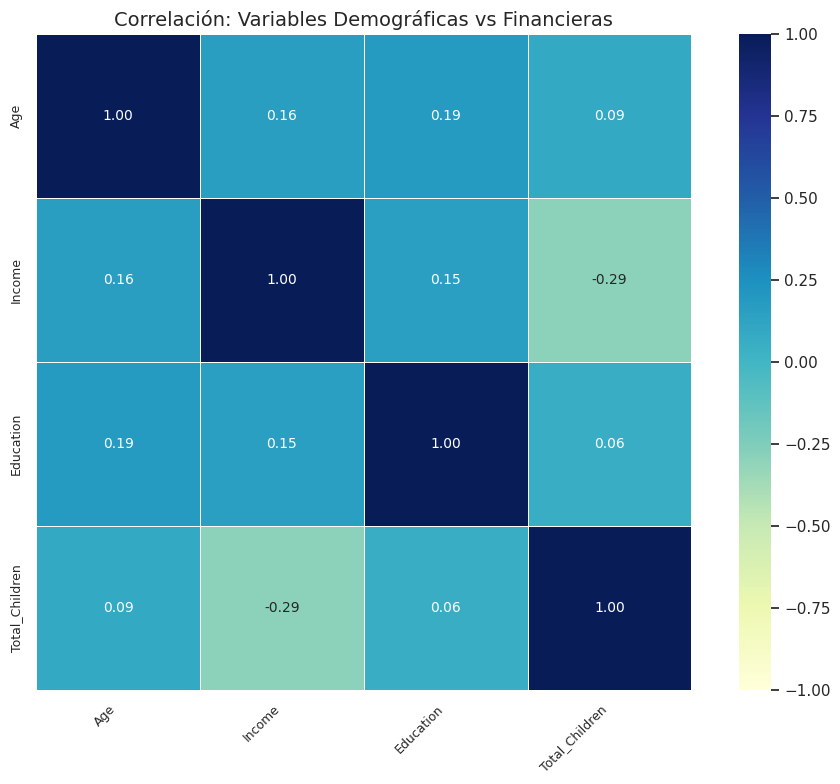

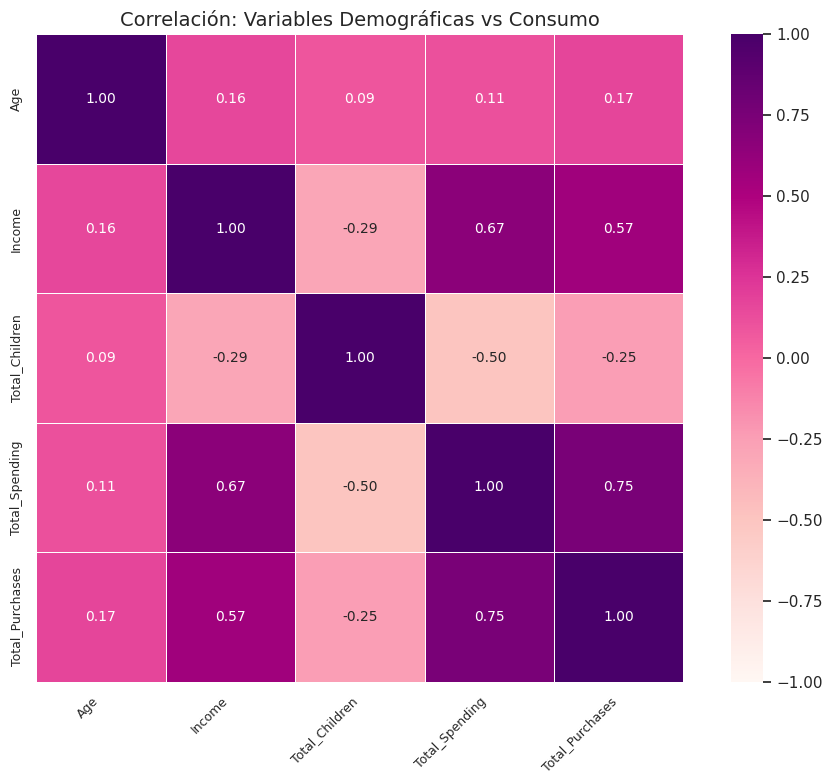

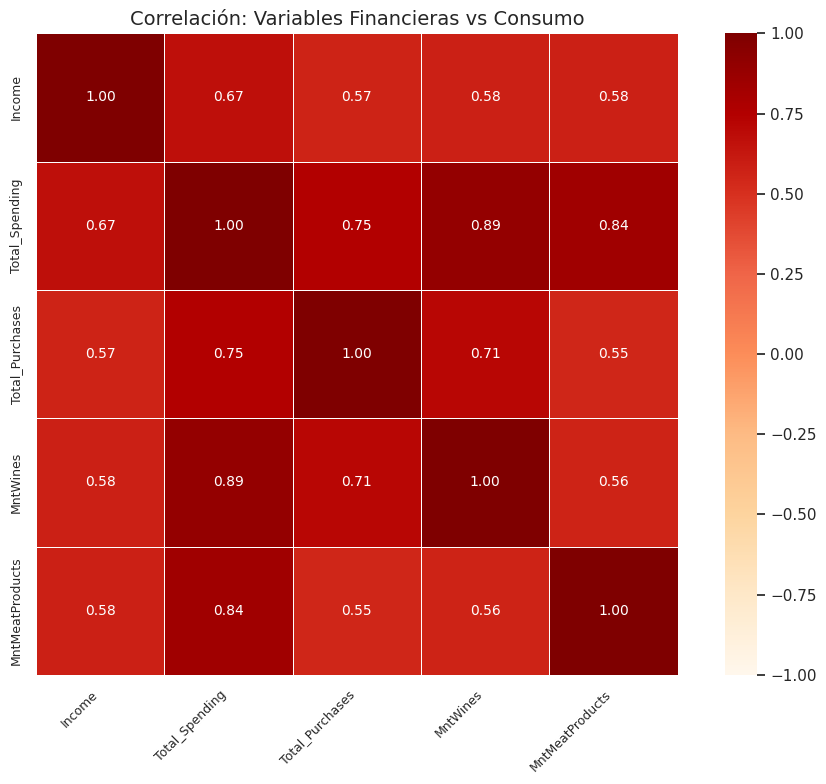

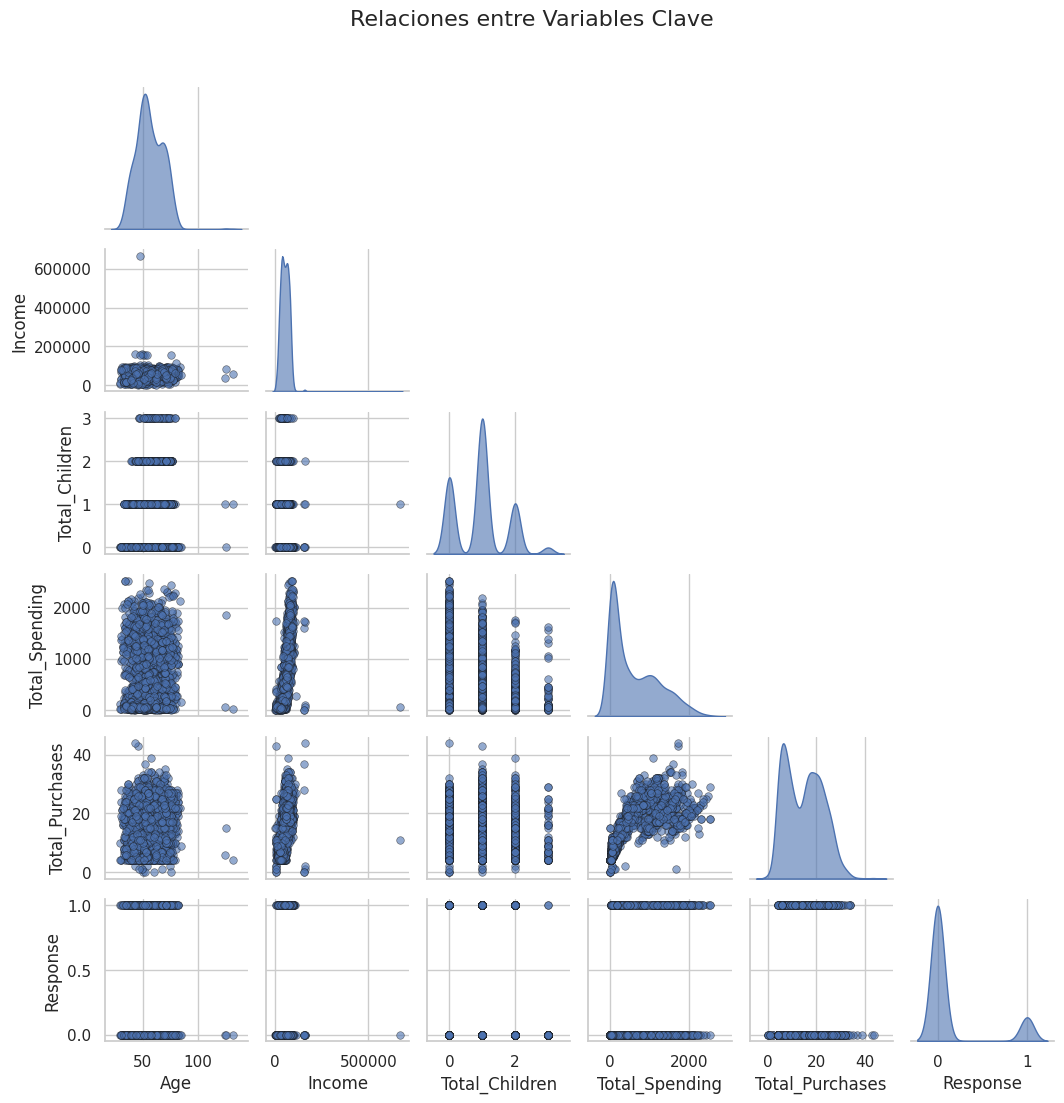

In [ ]:
# Segmentación por grupos de edad
# ======================================================================
age_bins = [0, 30, 45, 60, 100]
age_labels = ['<30', '30-45', '46-60', '>60']
df['Age_Group'] = pd.cut(df['Age'], bins=age_bins, labels=age_labels)

# Ingresos por grupo de edad
plt.figure(figsize=(10, 6))
sns.boxplot(x='Age_Group', y='Income', data=df, palette='viridis', order=age_labels)
plt.title('Distribución de Ingresos por Grupo de Edad', fontsize=14)
plt.xlabel('Grupo de Edad', fontsize=12)
plt.ylabel('Ingresos Anuales (USD)', fontsize=12)
plt.tight_layout()
plt.show()

# Relación entre Gasto Total y Compras Totales
# ======================================================================
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='Total_Purchases',
    y='Total_Spending',
    data=df,
    alpha=0.6,
    hue='Income',  # Cambiado de size a hue para mejor interpretación
    palette='viridis',
    size='Income',  # Opcional: mantener tamaño si se desea
    sizes=(20, 200)
)
plt.title('Relación entre Compras Totales y Gasto Total', fontsize=14)
plt.xlabel('Número Total de Compras', fontsize=12)
plt.ylabel('Gasto Total (USD)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(title='Ingresos', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

print(df.info())

# Preparación de datos para correlación
# ======================================================================
correlation_vars = [
    'Age', 'Income', 'Education', 'Total_Children', 'Recency',
    'Total_Spending', 'Total_Purchases',
    'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts',
    'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases',
    'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases',
    'NumWebVisitsMonth', 'Response'
]

corr_df = df[correlation_vars].copy()

# Matriz de correlación mejorada
# ======================================================================
plt.figure(figsize=(18, 15))
corr_matrix = corr_df.corr()

# Filtrar solo las correlaciones significativas (|r| >= 0.3)
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    annot_kws={"size": 10},
    cbar_kws={"shrink": 0.8},
    vmin=-1,  # Límites fijos para la escala de color
    vmax=1
)
plt.title('Matriz de Correlación (|r| >= 0.3)', fontsize=16)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()

# Análisis de correlaciones por categoría
# ======================================================================
def plot_correlation_subset(variables, title, cmap="viridis", figsize=(10, 8)):
    """Función auxiliar para graficar sub-matrices de correlación"""
    subset = corr_df[variables].corr()
    plt.figure(figsize=figsize)
    sns.heatmap(
        subset,
        annot=True,
        fmt=".2f",
        cmap=cmap,
        square=True,
        linewidths=0.5,
        annot_kws={"size": 10},  # Tamaño reducido para mejor ajuste
        vmin=-1,  # Escala fija
        vmax=1
    )
    plt.title(title, fontsize=14)
    plt.xticks(rotation=45, ha='right', fontsize=9)  # Rotación añadida
    plt.yticks(fontsize=9)
    plt.tight_layout()
    plt.show()

# 1. Demográficas vs Financieras
plot_correlation_subset(
    ['Age', 'Income', 'Education', 'Total_Children'],
    'Correlación: Variables Demográficas vs Financieras',
    cmap="YlGnBu"
)

# 2. Demográficas vs Consumo
plot_correlation_subset(
    ['Age', 'Income', 'Total_Children', 'Total_Spending', 'Total_Purchases'],
    'Correlación: Variables Demográficas vs Consumo',
    cmap="RdPu"
)

# 3. Financieras vs Consumo
plot_correlation_subset(
    ['Income', 'Total_Spending', 'Total_Purchases', 'MntWines', 'MntMeatProducts'],
    'Correlación: Variables Financieras vs Consumo',
    cmap="OrRd"
)

# Análisis de relaciones clave
# ======================================================================
key_vars = ['Age', 'Income', 'Total_Children', 'Total_Spending', 'Total_Purchases', 'Response']
g = sns.pairplot(
    df[key_vars],
    diag_kind='kde',
    corner=True,
    plot_kws={
        'alpha': 0.6,
        's': 30,  # Tamaño reducido
        'edgecolor': 'k'
    },
    diag_kws={
        'fill': True,
        'alpha': 0.6
    },
    height=1.8  # Controla el tamaño de cada subplot
)
g.fig.suptitle('Relaciones entre Variables Clave', y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

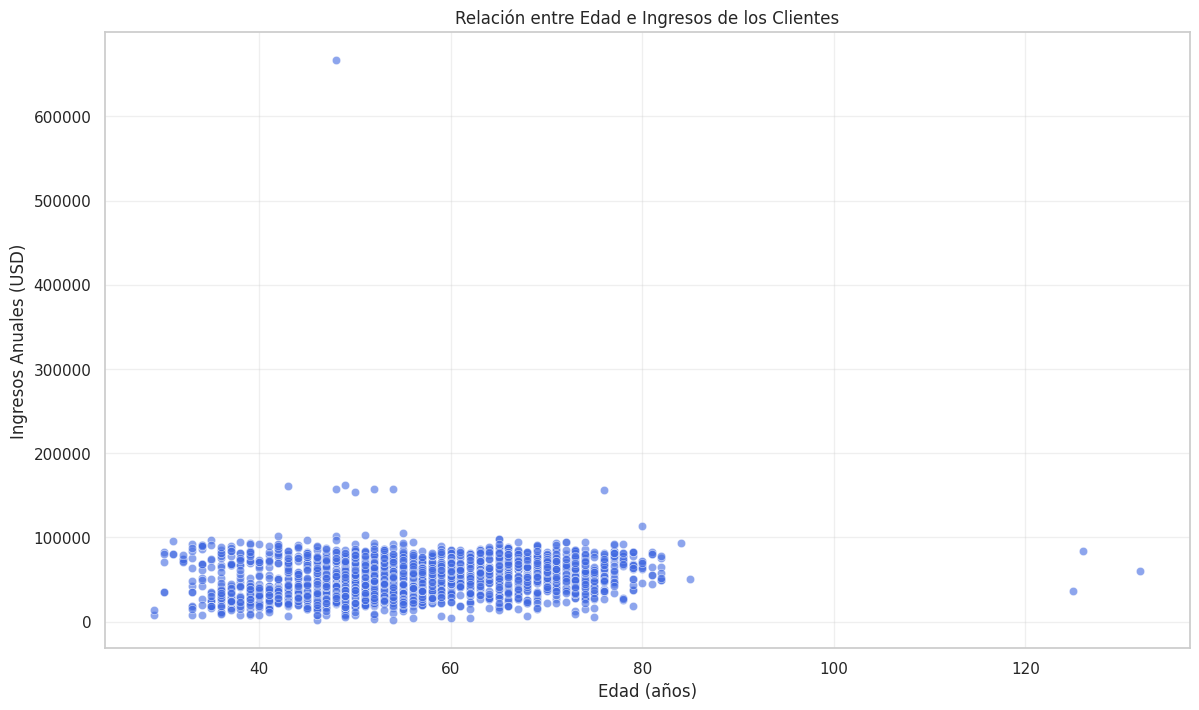

<ipython-input-154-f0b865f8b5ed>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Age_Group', y='Income', data=df, palette='viridis', order=age_labels)


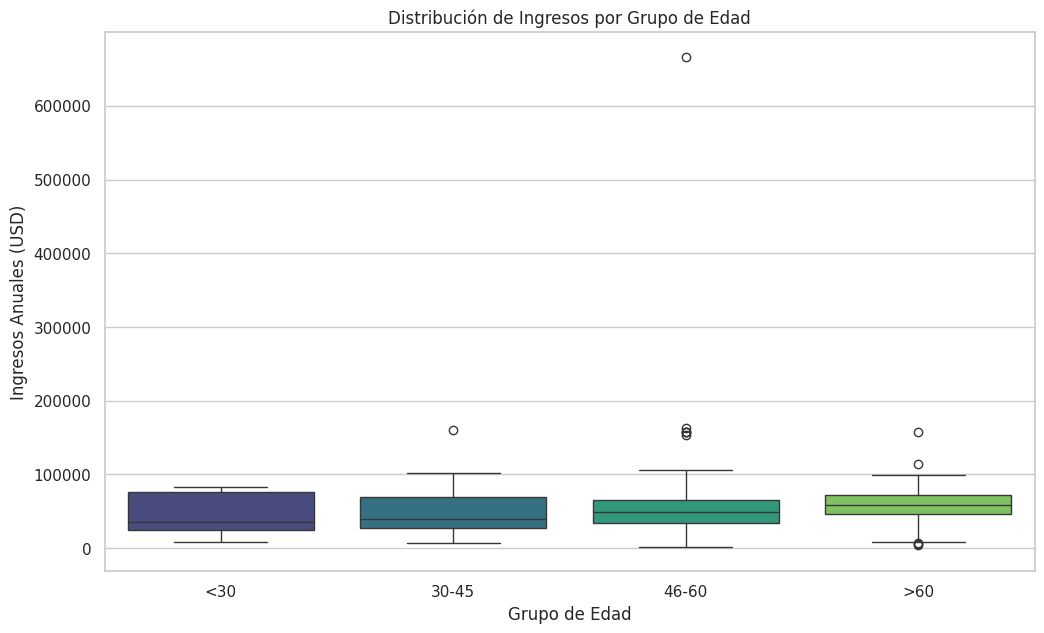

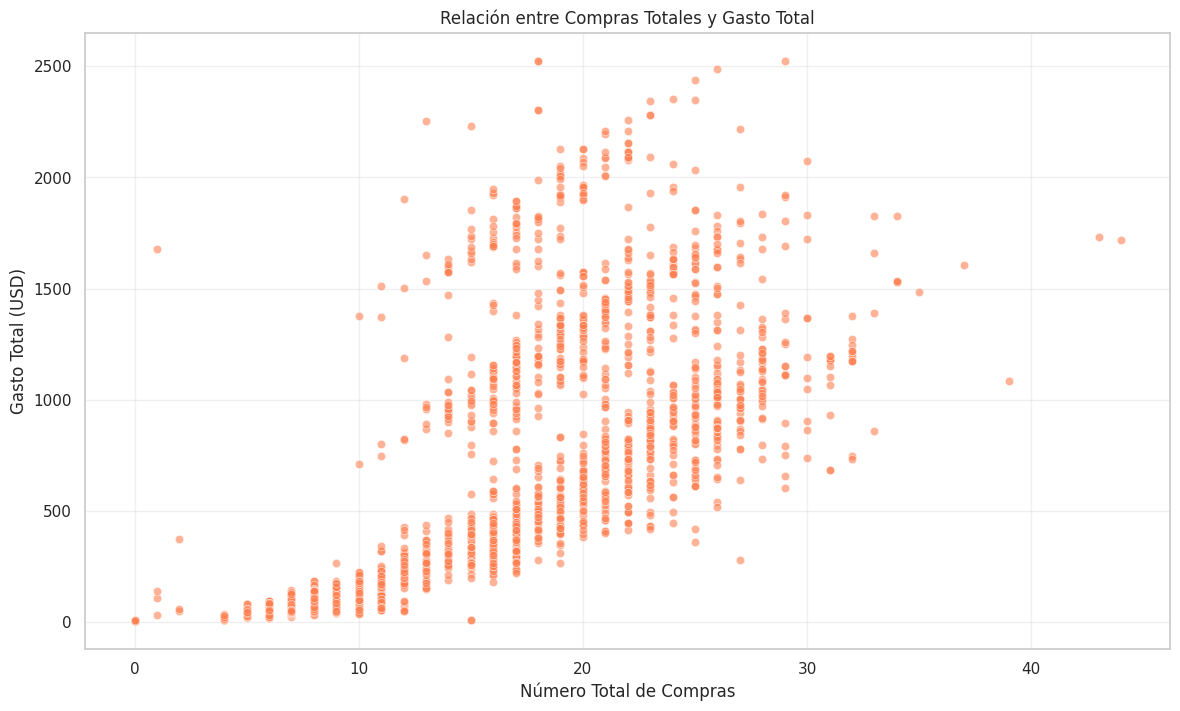

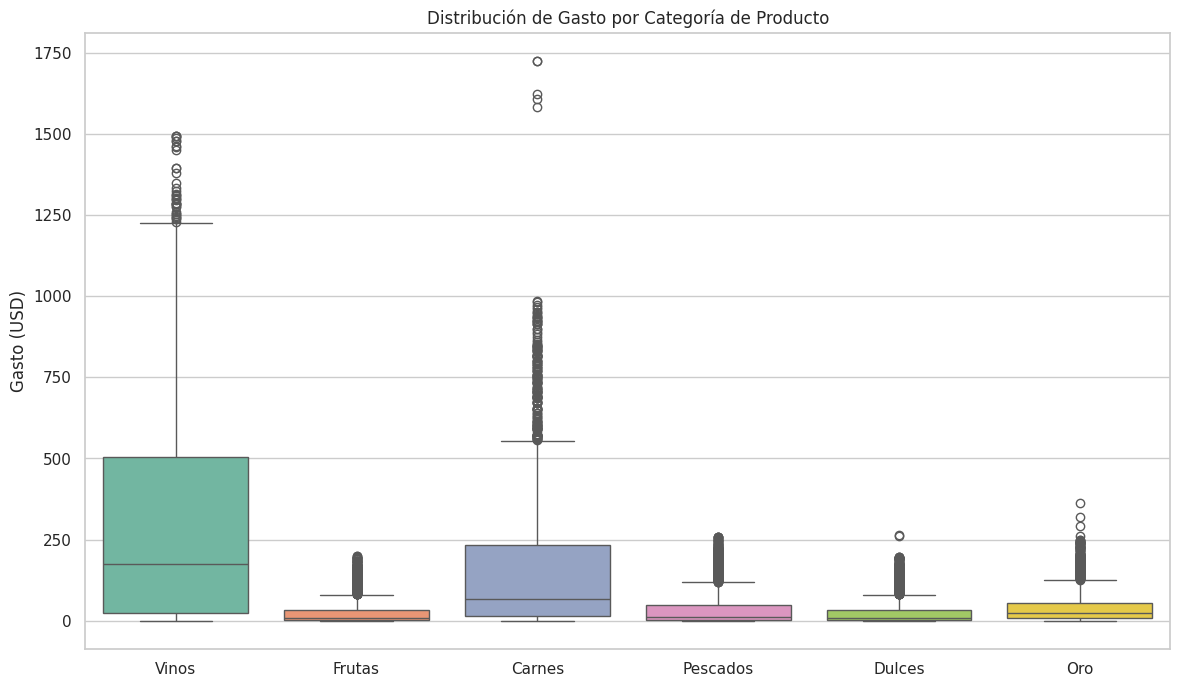

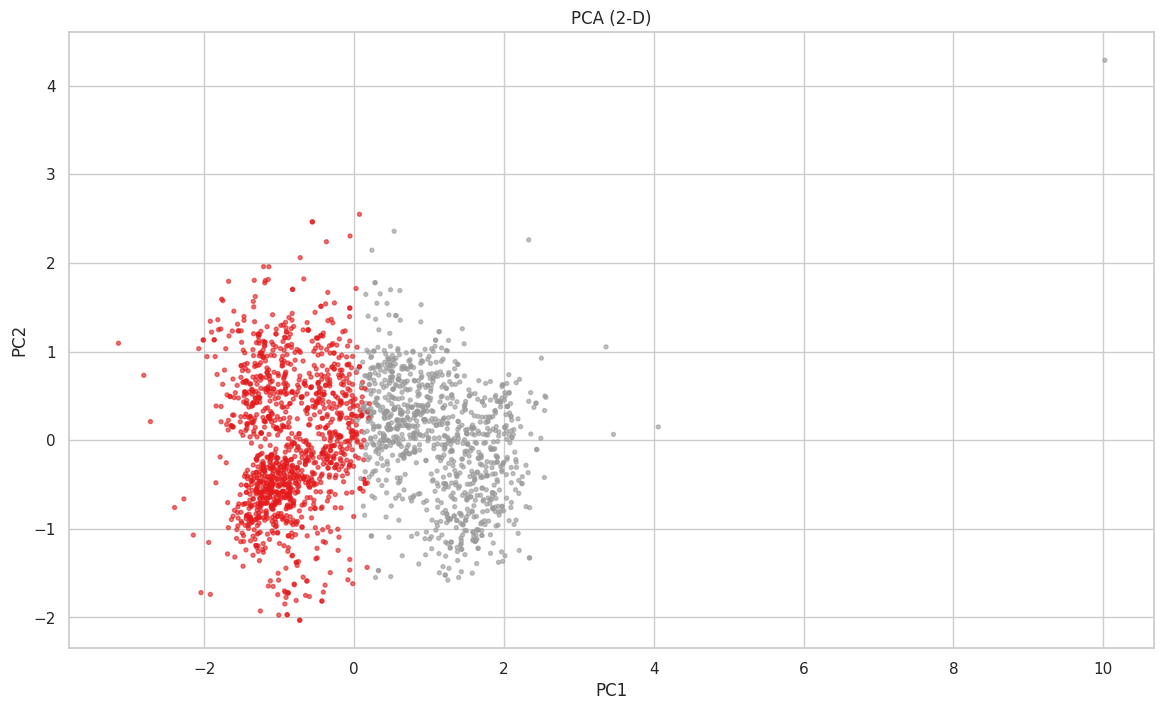

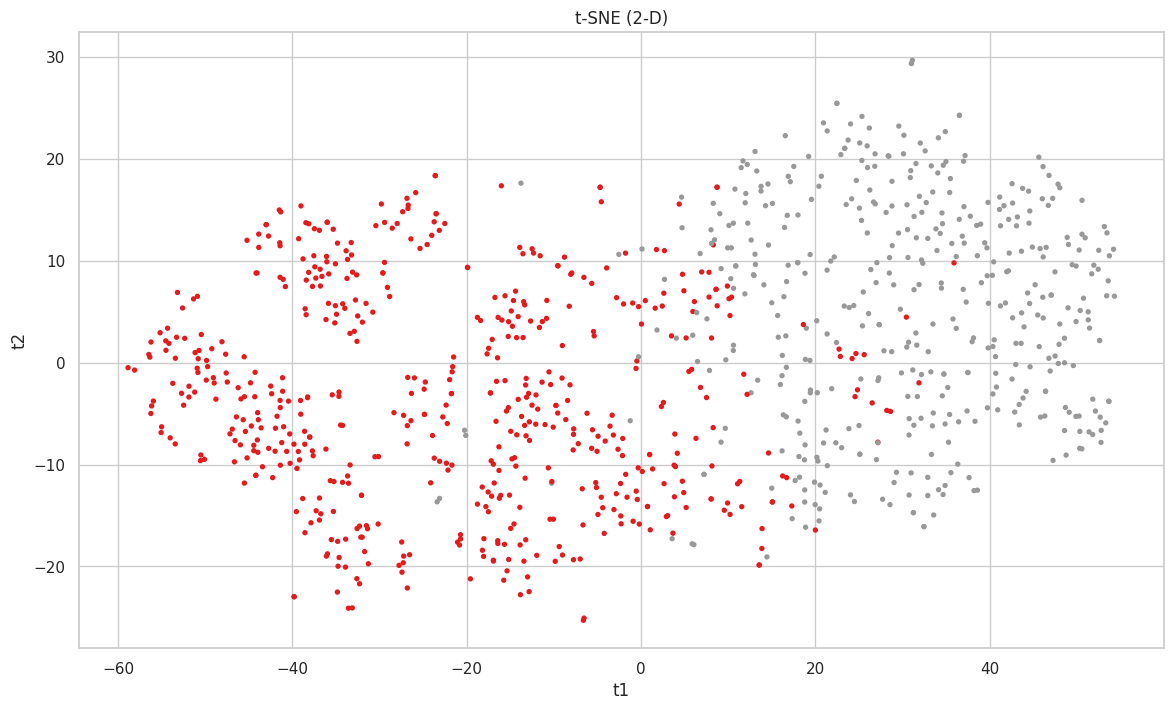

Error en visualización: name 'X_sample' is not defined


In [ ]:

# Configuración de estilo
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 12

# Cargar datos
df = pd.read_csv('MarketingCampaign.csv')

# 1. Preprocesamiento básico
# ======================================================================
# Calcular edad
current_year = 2025
df['Age'] = current_year - df['Year_Birth']

# Crear características compuestas
df['Total_Children'] = df['Kidhome'] + df['Teenhome']
df['Total_Spending'] = df[['MntWines', 'MntFruits', 'MntMeatProducts',
                          'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']].sum(axis=1)
df['Total_Purchases'] = df[['NumWebPurchases', 'NumCatalogPurchases',
                           'NumStorePurchases', 'NumDealsPurchases']].sum(axis=1)

# Consolidar estado civil
df['Marital_Status'] = df['Marital_Status'].replace({
    'Married': 'Partner',
    'Together': 'Partner',
    'Divorced': 'Single',
    'Widow': 'Single',
    'Alone': 'Single',
    'Absurd': 'Single',
    'YOLO': 'Single'
})

# Imputar ingresos faltantes
df['Income'] = df['Income'].fillna(df['Income'].median())

# 2. Análisis de variables demográficas (Edad e Ingresos)
# ======================================================================
# Relación entre Edad e Ingresos
plt.figure(figsize=(14, 8))
sns.scatterplot(x='Age', y='Income', data=df, alpha=0.6, color='royalblue')
plt.title('Relación entre Edad e Ingresos de los Clientes')
plt.xlabel('Edad (años)')
plt.ylabel('Ingresos Anuales (USD)')
plt.grid(True, alpha=0.3)
plt.show()
plt.close()

# Segmentación por grupos de edad
age_bins = [0, 30, 45, 60, 100]
age_labels = ['<30', '30-45', '46-60', '>60']
df['Age_Group'] = pd.cut(df['Age'], bins=age_bins, labels=age_labels)

# Ingresos por grupo de edad
plt.figure(figsize=(12, 7))
sns.boxplot(x='Age_Group', y='Income', data=df, palette='viridis', order=age_labels)
plt.title('Distribución de Ingresos por Grupo de Edad')
plt.xlabel('Grupo de Edad')
plt.ylabel('Ingresos Anuales (USD)')
plt.show()
plt.close()

# 3. Análisis de variables de consumo (Gasto Total y Compras Totales)
# ======================================================================
# Relación entre Gasto Total y Compras Totales
plt.figure(figsize=(14, 8))
sns.scatterplot(x='Total_Purchases', y='Total_Spending', data=df, alpha=0.6, color='coral')
plt.title('Relación entre Compras Totales y Gasto Total')
plt.xlabel('Número Total de Compras')
plt.ylabel('Gasto Total (USD)')
plt.grid(True, alpha=0.3)
plt.show()
plt.close()

# Distribución de gasto por categoría
product_cols = ['MntWines', 'MntFruits', 'MntMeatProducts',
               'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
product_names = ['Vinos', 'Frutas', 'Carnes', 'Pescados', 'Dulces', 'Oro']

plt.figure(figsize=(14, 8))
sns.boxplot(data=df[product_cols], palette='Set2')
plt.xticks(range(len(product_cols)), product_names)
plt.title('Distribución de Gasto por Categoría de Producto')
plt.ylabel('Gasto (USD)')
plt.show()
plt.close()

# 4. Segmentación de clientes
# ======================================================================
# Preparar datos para clustering
cluster_data = df[['Age', 'Income', 'Total_Spending', 'Total_Purchases']].copy()

# Escalar características
scaler = StandardScaler()
scaled_data = scaler.fit_transform(cluster_data)


# ── 5. Visualización PCA y t-SNE (opcional) ───────────────────────────────
# Usando los datos ya preprocesados
try:
    # PCA en 2 dimensiones
    pca = PCA(n_components=2, random_state=42).fit_transform(X)
    plt.scatter(pca[:, 0], pca[:, 1], c=y, cmap='Set1', s=8, alpha=0.6)
    plt.title('PCA (2-D)')
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.show()

   # t-SNE con submuestreo por eficiencia
    sample = min(1000, len(X))  # máximo 1000 puntos por rapidez
    tsne = TSNE(n_components=2, random_state=42).fit_transform(X_num[:sample])
    plt.scatter(tsne[:, 0], tsne[:, 1], c=y[:sample], cmap='Set1', s=8)
    plt.title('t-SNE (2-D)')
    plt.xlabel('t1'); plt.ylabel('t2')
    plt.show()

    tsne = TSNE(n_components=2, random_state=42).fit_transform(X_sample)
    plt.scatter(tsne[:, 0], tsne[:, 1], c=y_sample, cmap='Set1', s=8, alpha=0.6)
    plt.title('t-SNE (2-D)')
    plt.xlabel('t1')
    plt.ylabel('t2')
    plt.show()
except Exception as e:
    print(f"Error en visualización: {str(e)}")

In [ ]:
df.head()

### K-MEANS

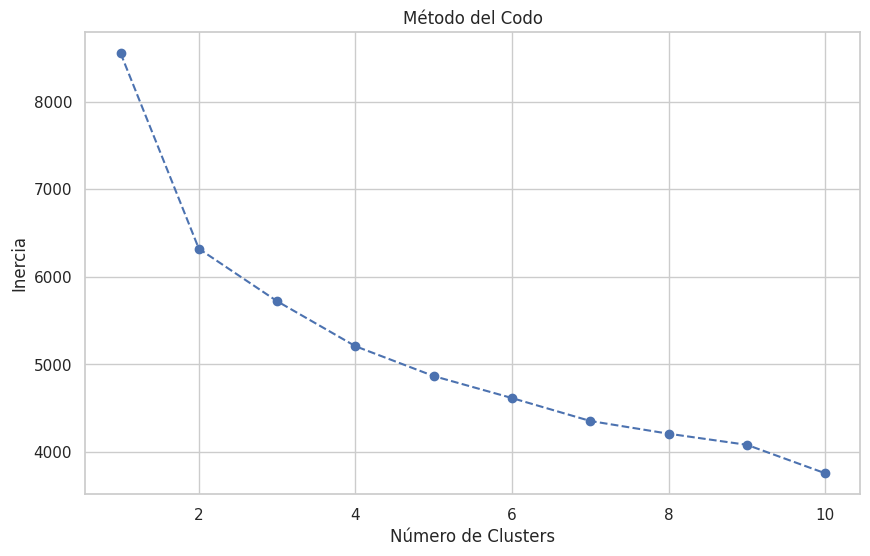

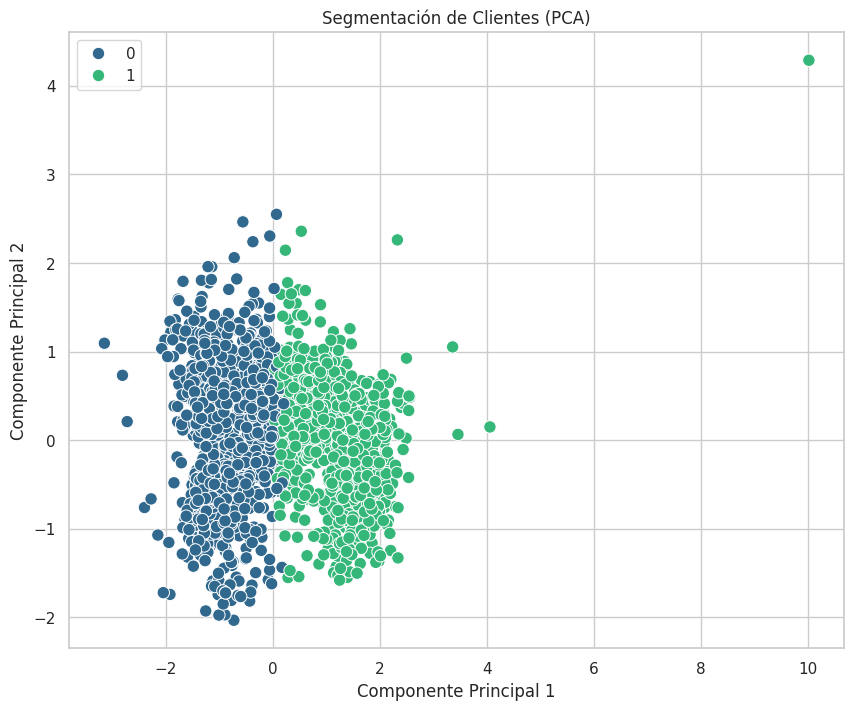

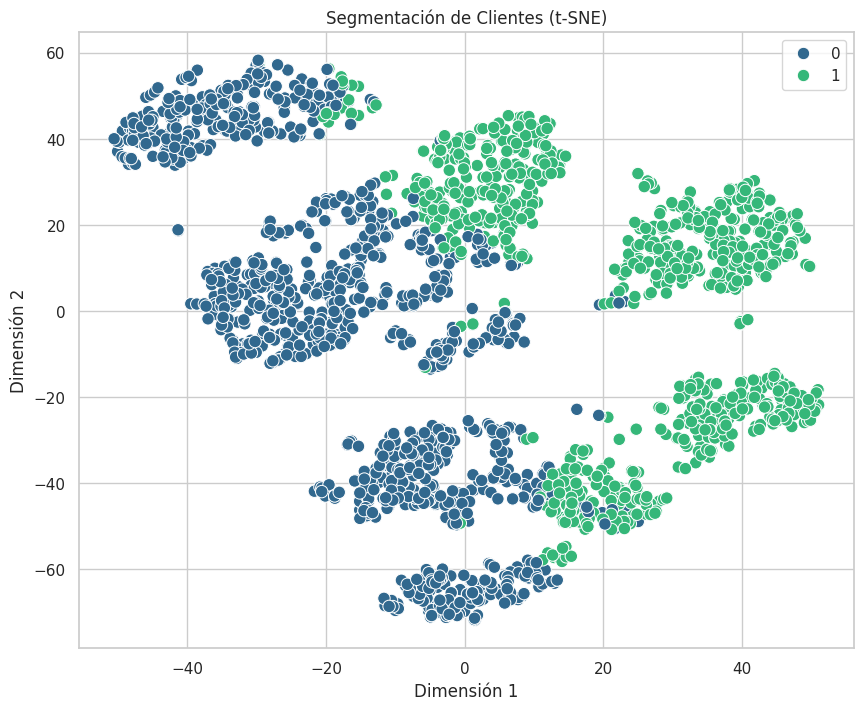

<ipython-input-152-2c898e2529b4>:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette='viridis')


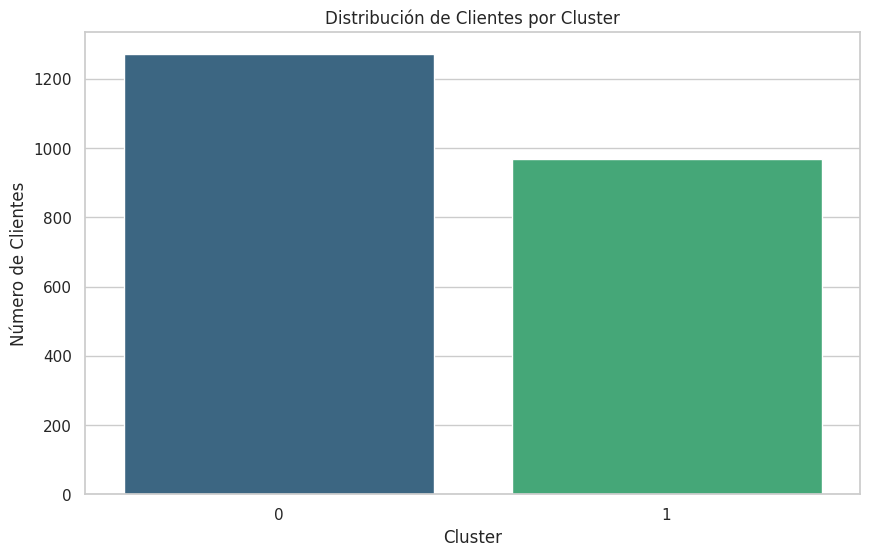

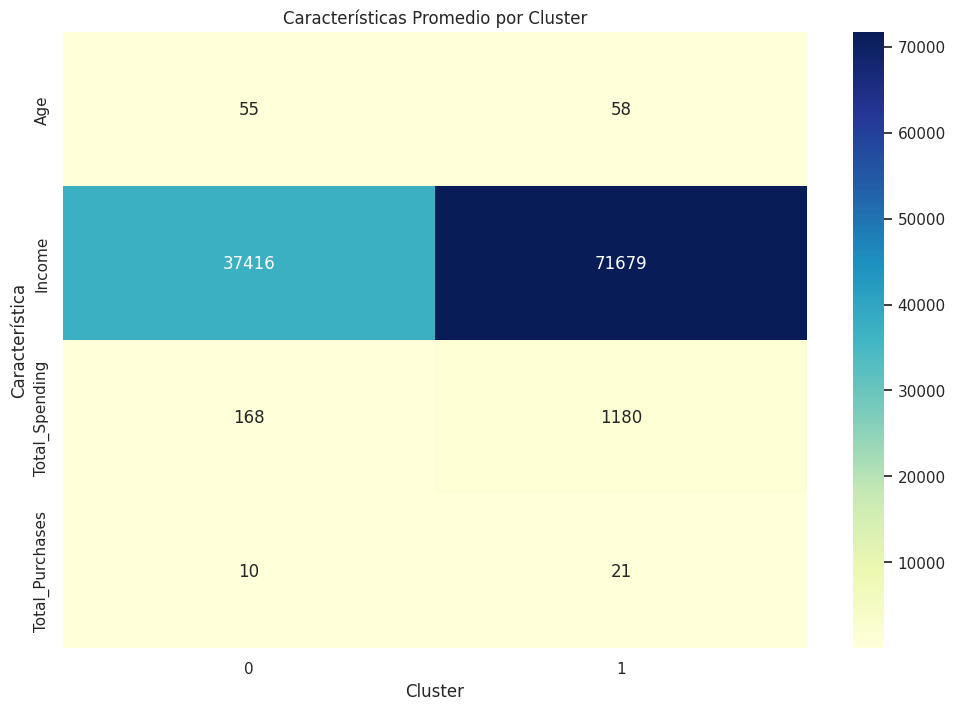

In [ ]:
# Método del codo para clustering
inertia = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(preprocessed_data)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), inertia, marker='o', linestyle='--')
plt.title('Método del Codo')
plt.xlabel('Número de Clusters')
plt.ylabel('Inercia')
plt.show()
plt.close()

# Seleccionar k=2 basado en el método del codo
optimal_clusters = 2
kmeans = KMeans(n_clusters=optimal_clusters, random_state=42)
clusters = kmeans.fit_predict(preprocessed_data)
df['Cluster'] = clusters

# Visualización con PCA
pca = PCA(n_components=2)
pca_result = pca.fit_transform(preprocessed_data)

plt.figure(figsize=(10, 8))
sns.scatterplot(x=pca_result[:,0], y=pca_result[:,1], hue=clusters, palette='viridis', s=80)
plt.title('Segmentación de Clientes (PCA)')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.show()
plt.close()

# Visualización con t-SNE
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
tsne_result = tsne.fit_transform(preprocessed_data)

plt.figure(figsize=(10, 8))
sns.scatterplot(x=tsne_result[:,0], y=tsne_result[:,1], hue=clusters, palette='viridis', s=80)
plt.title('Segmentación de Clientes (t-SNE)')
plt.xlabel('Dimensión 1')
plt.ylabel('Dimensión 2')
plt.show()
plt.close()


# 5. Análisis de clusters
# ======================================================================
# Tamaño de cada cluster
plt.figure(figsize=(10, 6))
cluster_counts = df['Cluster'].value_counts().sort_index()
sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette='viridis')
plt.title('Distribución de Clientes por Cluster')
plt.xlabel('Cluster')
plt.ylabel('Número de Clientes')
plt.show()
plt.close()

# Características promedio por cluster
cluster_analysis = df.groupby('Cluster')[['Age', 'Income', 'Total_Spending', 'Total_Purchases']].mean()

plt.figure(figsize=(12, 8))
sns.heatmap(cluster_analysis.T, annot=True, cmap='YlGnBu', fmt=".0f")
plt.title('Características Promedio por Cluster')
plt.xlabel('Cluster')
plt.ylabel('Característica')
plt.show()
plt.close()


Tomé en cuenta más hiperparámetros para el siguiente dataset

### Métodos de ML


♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥  LogReg  ♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥
Best CV accuracy: 0.998
Best params: {'C': 10, 'penalty': 'l1'}
              precision    recall  f1-score   support

           0      1.000     1.000     1.000       254
           1      1.000     1.000     1.000       194

    accuracy                          1.000       448
   macro avg      1.000     1.000     1.000       448
weighted avg      1.000     1.000     1.000       448



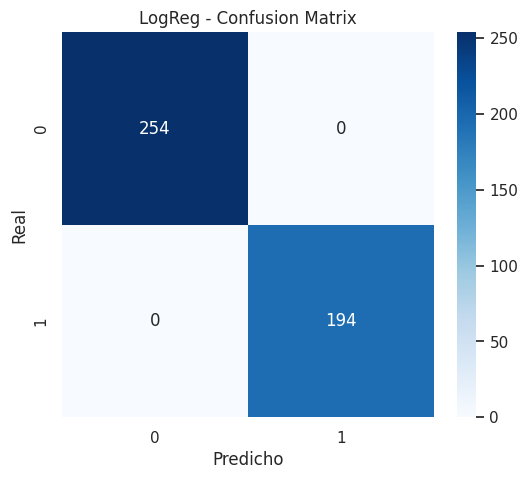


♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥  KNN  ♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥
Best CV accuracy: 0.977
Best params: {'n_neighbors': 7, 'weights': 'distance'}
              precision    recall  f1-score   support

           0      0.988     0.984     0.986       254
           1      0.979     0.985     0.982       194

    accuracy                          0.984       448
   macro avg      0.984     0.984     0.984       448
weighted avg      0.984     0.984     0.984       448



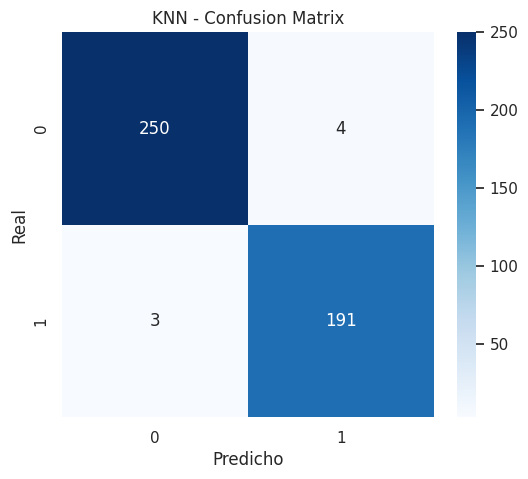


♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥  Tree  ♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥
Best CV accuracy: 0.970
Best params: {'max_depth': 5, 'min_samples_split': 2}
              precision    recall  f1-score   support

           0      0.961     0.969     0.965       254
           1      0.958     0.948     0.953       194

    accuracy                          0.960       448
   macro avg      0.960     0.958     0.959       448
weighted avg      0.960     0.960     0.960       448



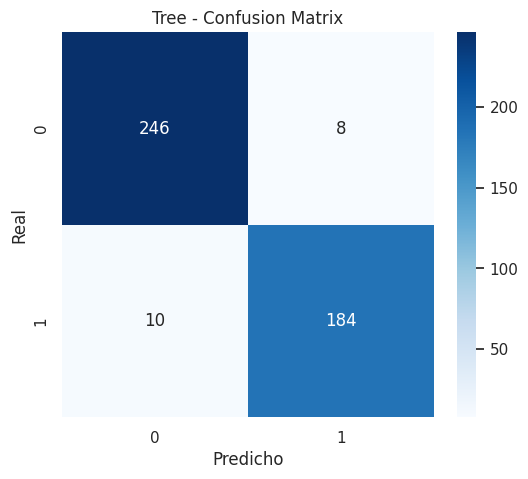


♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥  RF  ♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥
Best CV accuracy: 0.980
Best params: {'max_depth': 10, 'min_samples_leaf': 2, 'n_estimators': 200}
              precision    recall  f1-score   support

           0      0.973     0.980     0.976       254
           1      0.974     0.964     0.969       194

    accuracy                          0.973       448
   macro avg      0.973     0.972     0.973       448
weighted avg      0.973     0.973     0.973       448



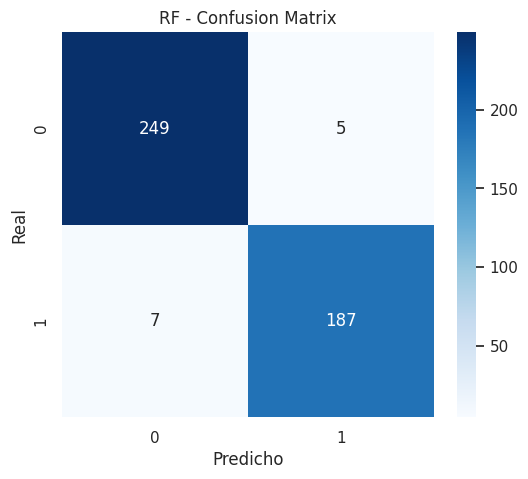


♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥  XGB  ♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥♥


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [02:10:39] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


Best CV accuracy: 0.986
Best params: {'subsample': 0.8, 'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.1}
              precision    recall  f1-score   support

           0      0.980     0.984     0.982       254
           1      0.979     0.974     0.977       194

    accuracy                          0.980       448
   macro avg      0.980     0.979     0.980       448
weighted avg      0.980     0.980     0.980       448



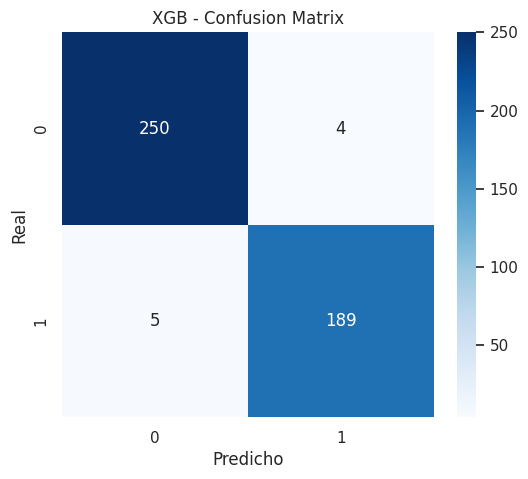

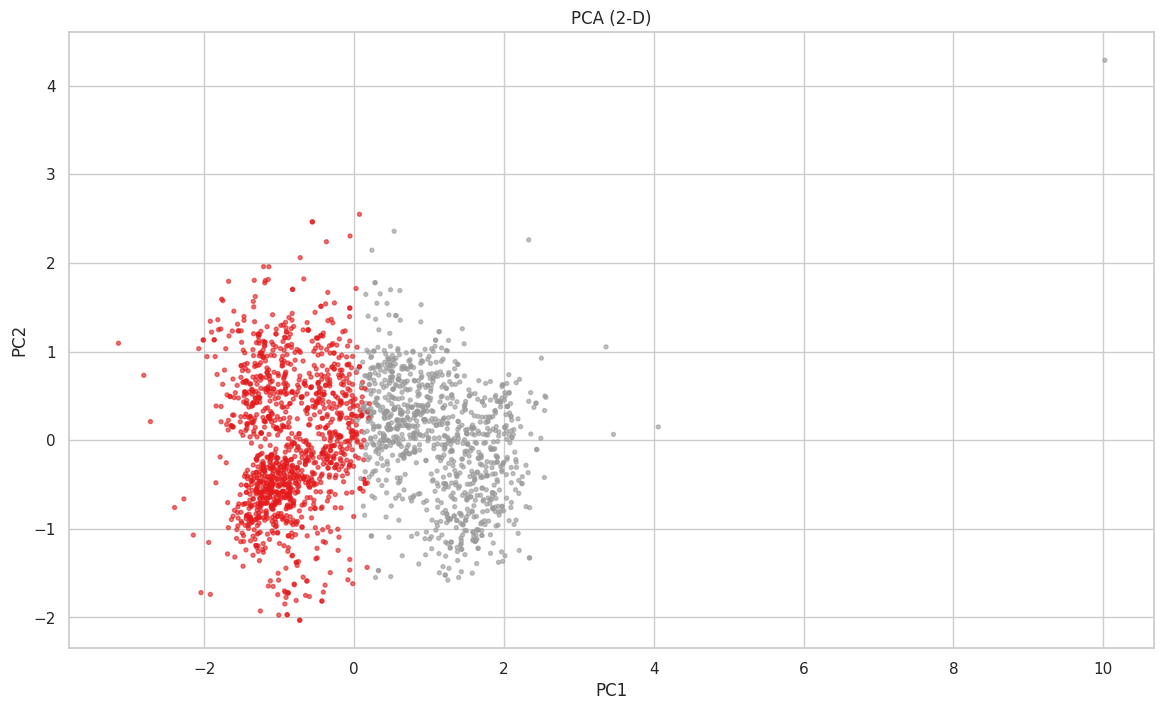

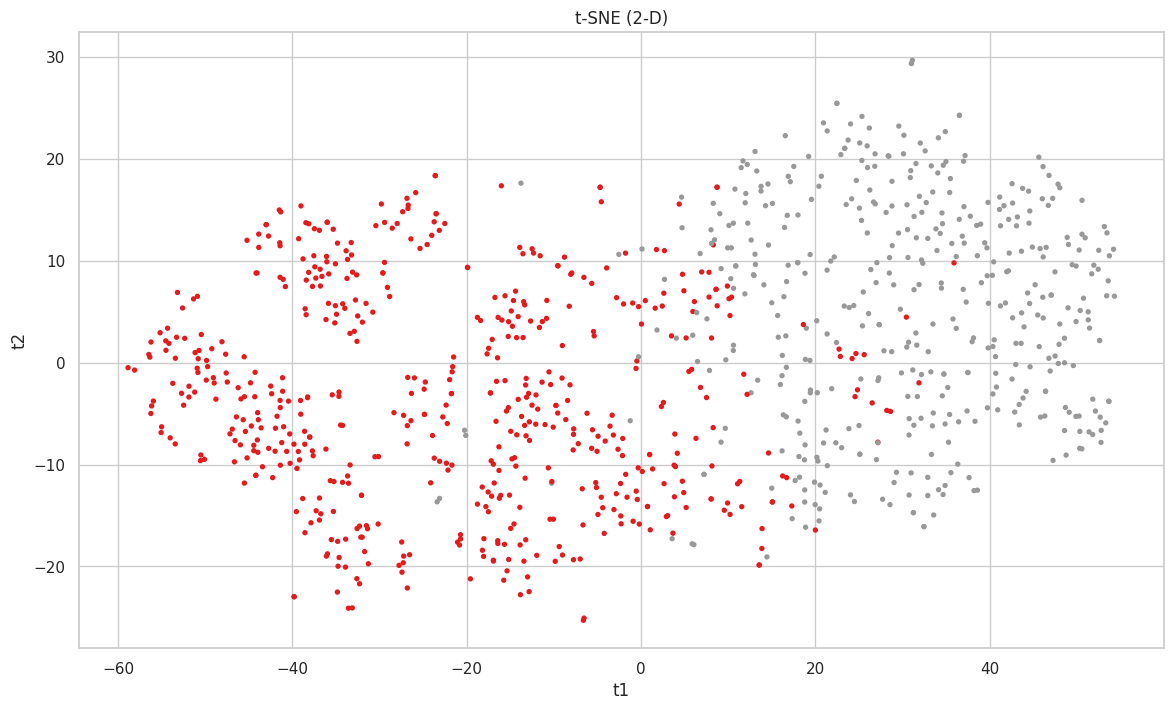

Error en visualización: name 'X_sample' is not defined


In [ ]:
# ── 1. Datos de entrada ───────────────────────────────────────────────────
X = preprocessed_data           # matriz ya transformada
y = clusters                    # etiquetas: cluster_id por observación

# ── 2. División train/test ────────────────────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ── 3. Modelos base ───────────────────────────────────────────────────────
modelos = {
    'LogReg': LogisticRegression(max_iter=1000, class_weight='balanced', solver='liblinear'),
    'KNN': KNeighborsClassifier(),
    'Tree': DecisionTreeClassifier(random_state=42),
    'RF': RandomForestClassifier(random_state=42),
    'XGB': XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
}

# ── 4. Grids de hiperparámetros ───────────────────────────────────────────
param_grids = {
    'LogReg': {
        'C': [0.01, 0.1, 1, 10],
        'penalty': ['l1', 'l2']
    },
    'KNN': {
        'n_neighbors': [3, 5, 7, 9],
        'weights': ['uniform', 'distance']
    },
    'Tree': {
        'max_depth': [None, 5, 10, 20],
        'min_samples_split': [2, 5, 10]
    },
    'RF': {
        'n_estimators': [200, 500],
        'max_depth': [None, 10, 20],
        'min_samples_leaf': [1, 2, 4]
    },
    'XGB': {
        'n_estimators': [200, 400],
        'learning_rate': [0.01, 0.1],
        'max_depth': [3, 6, 9],
        'subsample': [0.8, 1.0]
    }
}

# ── 5. Búsqueda de hiperparámetros y evaluación ───────────────────────────
for nombre, modelo in modelos.items():
    print(f'\n{"♥"*25}  {nombre}  {"♥"*25}')

    # Seleccionar el tipo de búsqueda
    if nombre == 'XGB':
        search = RandomizedSearchCV(
            modelo, param_grids[nombre], n_iter=12, scoring='accuracy',
            cv=cv5, n_jobs=-1, verbose=0, random_state=42)
    else:
        search = GridSearchCV(
            modelo, param_grids[nombre], scoring='accuracy',
            cv=cv5, n_jobs=-1, verbose=0)

    # Entrenamiento y búsqueda
    search.fit(X_train, y_train)

    # Resultados
    print(f'Best CV accuracy: {search.best_score_:.3f}')
    print(f'Best params: {search.best_params_}')

    # Evaluación en test
    y_pred = search.predict(X_test)
    print(classification_report(y_test, y_pred, digits=3))

    # Matriz de confusión
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(6,5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'{nombre} - Confusion Matrix')
    plt.xlabel('Predicho')
    plt.ylabel('Real')
    plt.show()
